# A tour of STARfinder stitching and assembly: place, assemble and export a synthetic sample

This notebook introduces §2.10 of the maintained Python package: placing the fields of view
(FOVs) of a sample in one physical frame, assembling their §2.9 results into sample tables,
and writing the sample's outputs. The code lives in `starfinder.stitching`,
`starfinder.assembly` and `starfinder.export`, and `Dataset` in `starfinder.dataset`
holds the two sample-level entries, `Dataset.stitch` and `Dataset.export`. The export reaches the
sample's cells by one of two routes: segmentation per FOV followed by assembly, or segmentation of
the fused image. Like the §2.6 to
§2.9 tours (`starfinder_registration_tour.ipynb`, `starfinder_spot_finding_tour.ipynb`,
`starfinder_readout_tour.ipynb`, `starfinder_segmentation_assignment_tour.ipynb`), it runs
every piece through the public API, on a small synthetic sample whose answers are known:

1. the two sample-level entries and the export folder;
2. a synthetic sample;
3. the tile position table;
4. a placement: the truth through `placement_from_table`, then `multiview_stitcher`;
5. the per-FOV §2.9 results through mask import, and the goodSpots tables;
6. `Dataset.export` on the route per FOV, and its parts;
7. ownership regions;
8. statuses, reasons and flags;
9. the count identities, with the duplicate rule;
10. `sample.h5ad`;
11. the default fused projection and its geometry;
12. the label export at 0.25;
13. the SpatialData export and `lookup_source`;
14. a part that cannot run;
15. the two routes and the setting `route`;
16. the duplicate rule of the route per FOV;
17. the route after fusion;
18. `compare_routes`: the two routes side by side;
19. the cell flags on the two routes;
20. what is deferred: viewers, a fused 3D stack, merging of cells;
21. clean up.

Every section first explains a design choice and then runs the code that shows it. The design
is specified in ten pages accepted at W-329 and two pages accepted at the review W-377 for the
route after fusion (section 1); the notebook links those pages rather than repeating them. **It is
not a benchmark.** It ranks no placement backend and no route, recommends no backend, route,
setting, threshold or tolerance and makes no accuracy statement: the placement that the export
uses is the scene's own truth, supplied rather than measured, the numbers printed about
`multiview_stitcher` are a measurement on four small tiles, not a qualification, and the cells of
the route after fusion come from a seeded watershed chosen because it needs no model.

**Scope and resources.** The sample is the `sample-tiny-v1` preset of the synthetic sample
scene (seed 42): 2 × 2 FOVs of 5 × 36 × 36 voxels cut from one scene of 6 × 63 × 63, inside the
routine bound of the §2.10 resource exceptions (tiles cut from one scene of at most
16 × 256 × 256, one CPU, 4 GiB, 1800 s; section 21 checks the sizes). The notebook needs no
real data, MATLAB, Fiji, GPU, network access or model file: the route after fusion imports the
scene's truth nuclei and grows the cells with a seeded watershed. Three optional extras serve
parts of it: `multiview-stitcher` (the second placement of section 4, the fused image, the
label export and the route after fusion), `spatialdata` (the store of section 13) and
`anndata` (`sample.h5ad`, which the assemble part of `Dataset.export` writes). A cell that needs a missing extra prints why it is
skipped, and `Dataset.export` records the part it cannot run, so the notebook also runs
without them. Every random draw comes from a fixed seed, dask runs with the synchronous
scheduler and the numerical libraries run on one thread, so a second execution prints the
same numbers on the same host and library build, except the wall-clock timings that section
21 collects. Files are written only under a temporary directory that the notebook creates and
removes in its last cell.

To execute it from `src/python` in the locked environment (the `dev` group provides Jupyter),
with one numerical thread and no GPU:

```bash
export OMP_NUM_THREADS=1 MKL_NUM_THREADS=1 OPENBLAS_NUM_THREADS=1 CUDA_VISIBLE_DEVICES=""
uv run jupyter nbconvert --to notebook --execute --output-dir <new directory> \
    ../../example/introduction/starfinder_stitching_assembly_tour.ipynb
```

The setup cell draws figures inline. It keeps the numerical libraries on one thread (set before
NumPy is imported) and hides any GPU. It checks that `starfinder` is imported from the checkout
that holds this notebook, and that importing the three §2.10 modules imports neither
multiview-stitcher nor spatialdata nor zarr: a part imports its library only when it runs. Then
it tries each optional extra once and records which are importable. Everything the notebook
writes goes to a new temporary workspace, which section 21 removes. The helpers defined here:

* `clean` writes that workspace as `<workspace>`, so no machine-specific path is printed;
* `error_of` prints the error a call raises;
* `timed` records the wall time of the slower steps for section 21;
* `synchronous` runs dask's synchronous scheduler (one thread, a fixed order);
* `files_under` lists the files of a folder.

The deprecation warnings that some libraries issue on import are silenced there, and so is
`ome_zarr`'s informational logging, because both print environment-specific text.

In [1]:
%matplotlib inline
import os

for variable in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS", "NUMEXPR_NUM_THREADS",
                 "NUMBA_NUM_THREADS"):
    os.environ.setdefault(variable, "1")
os.environ.setdefault("CUDA_VISIBLE_DEVICES", "")

import importlib
import inspect
import json
import logging
import sys
import tempfile
import time
import warnings
from contextlib import contextmanager, nullcontext
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import starfinder
import starfinder.assembly
import starfinder.export
import starfinder.stitching

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", 80)

REPOSITORY = Path(starfinder.__file__).resolve().parents[3]
LIBRARIES = ("multiview_stitcher", "spatialdata", "zarr")
print("starfinder imported from:", Path(starfinder.__file__).resolve().relative_to(REPOSITORY).as_posix())
print("the same checkout as this notebook:", Path.cwd().resolve().is_relative_to(REPOSITORY))
print("libraries imported by the §2.10 modules:", {name: name in sys.modules for name in LIBRARIES})
print("threads:", {v: os.environ[v] for v in ("OMP_NUM_THREADS", "NUMBA_NUM_THREADS")},
      " CUDA_VISIBLE_DEVICES:", repr(os.environ["CUDA_VISIBLE_DEVICES"]))


def importable(name):
    # Whether an optional extra can be imported; the import happens here, once, without the libraries'
    # own deprecation warnings (they name files of the environment, not of this notebook).
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        try:
            importlib.import_module(name)
        except ImportError:
            return False
    return True


EXTRAS = {"multiview-stitcher": importable("multiview_stitcher"), "spatialdata": importable("spatialdata"),
          "anndata": importable("anndata")}
print("extras importable:", EXTRAS)
# ome_zarr logs a line with an object address when spatialdata reads a label image back; keep it quiet.
logging.getLogger("ome_zarr").setLevel(logging.ERROR)

_workspace = tempfile.TemporaryDirectory(prefix="starfinder-stitching-assembly-tour-")
WORKSPACE = Path(_workspace.name)
TIMINGS = {}


def clean(text):
    # Write the temporary workspace as <workspace>.
    return str(text).replace(str(WORKSPACE.resolve()), "<workspace>").replace(str(WORKSPACE), "<workspace>")


def error_of(call):
    # Run call, which must raise; return "<error type>: <message>" with clean paths.
    try:
        call()
    except Exception as error:
        return clean(f"{type(error).__name__}: {error}")
    raise AssertionError("expected an error")


def skipped(reason):
    print(f"skipped: {reason}")


@contextmanager
def timed(label):
    start = time.perf_counter()
    yield
    TIMINGS[label] = time.perf_counter() - start


def synchronous():
    # dask's synchronous scheduler when dask is importable (it comes with the multiview-stitcher extra).
    try:
        import dask
    except ImportError:
        return nullcontext()
    return dask.config.set(scheduler="synchronous")


def files_under(root):
    # The relative POSIX paths of the files under root, sorted.
    return sorted(p.relative_to(root).as_posix() for p in Path(root).rglob("*") if p.is_file())


print("workspace: a new temporary directory, removed at the end")

starfinder imported from: src/python/starfinder/__init__.py
the same checkout as this notebook: True
libraries imported by the §2.10 modules: {'multiview_stitcher': False, 'spatialdata': False, 'zarr': False}
threads: {'OMP_NUM_THREADS': '1', 'NUMBA_NUM_THREADS': '1'}  CUDA_VISIBLE_DEVICES: ''


extras importable: {'multiview-stitcher': True, 'spatialdata': True, 'anndata': True}
workspace: a new temporary directory, removed at the end


## 1. The two sample-level entries and the export folder

**Terms** ([docs/stitching-contract.md](../../docs/stitching-contract.md), "Terms";
[docs/assembly-contract.md](../../docs/assembly-contract.md), "Terms";
[docs/sample-output-contract.md](../../docs/sample-output-contract.md), "Terms"):

* the **sample frame** `sample:<sample>` is one physical frame in µm, with identity direction;
* a FOV's **origin** is the sample-frame position of index `(0, 0, 0)` of its reference grid,
  so a FOV index `p` lies at `origin + p ⊙ spacing`; a measured placement fixes its free
  translation by a gauge (G1), a supplied one has none;
* a **placement** (`PlacementResult`) holds one row per FOV (status, origin, correction,
  flags), one row per neighbour pair, and a record with the method, the review and its
  approvals, whichever backend made it;
* the **owner** of a sample point is the FOV whose region holds it (section 7); a cell or
  molecule is **retained** by its own FOV when that FOV owns it, else **excluded** with a
  reason, and nothing is matched or merged across FOVs.

**Two entries per sample.** Per FOV, §2.6 to §2.9 have their own calls (`FOV.run`,
`FOV.segment`, `FOV.assign`). The sample has two, and both are sample-level computations on
saved files, not multi-FOV runners:

1. `Dataset.stitch(sample, fov_ids=…, table=…, config=…)` reads each FOV's saved image and
   calls `stitch` with one method of `STITCHING_METHODS`; it saves the placement under
   `stitching/<sample>/`. `placement_from_table` builds the same record from a known
   placement, and BigStitcher's `dataset.xml` is read by `import_bigstitcher`;
2. `Dataset.export(sample, placement=…, assignment=…, config=…, output_dir=…)` reaches the
   sample's cells by one of two routes, which `ExportConfig.route` chooses (section 15). On the
   route per FOV it calls four parts in order, `assemble`, `fuse`, `fuse_labels` and
   `export_spatialdata`; on the route after fusion five, `fuse`, `segment`, `assemble`,
   `fuse_labels` and `export_spatialdata`
   ([docs/sample-segmentation-contract.md](../../docs/sample-segmentation-contract.md), "The
   parts on each route"). Each part is turned on or off by `ExportConfig`, and everything goes
   into one folder, `export/<sample>/`, with one record `export.json` that has a section per
   part ([docs/sample-output-contract.md](../../docs/sample-output-contract.md), "The export
   entry").

The cell prints both signatures and the parts with their defaults: the label export and the
SpatialData export are off unless asked for, and `route` is not set, so it follows
`dimensionality`.

In [2]:
from starfinder.dataset import Dataset
from starfinder.export import ROUTES, ExportConfig

entries = pd.DataFrame([
    dict(entry="Dataset.stitch", writes="stitching/<sample>/ (placement)", signature=Dataset.stitch),
    dict(entry="Dataset.export", writes="export/<sample>/ (export.json and the parts' files)",
         signature=Dataset.export),
])
entries["signature"] = [str(inspect.signature(f)).replace("(self, ", "(") for f in entries.signature]
with pd.option_context("display.max_colwidth", 400):
    display(entries)

DEFAULTS = ExportConfig()
parts = pd.DataFrame([
    dict(order_per_fov=1, order_after_fusion=3, part="assemble", on_by_default=DEFAULTS.assemble,
         writes=f"tables/*.{DEFAULTS.table_format}, sample.h5ad", section="assembly"),
    dict(order_per_fov=2, order_after_fusion=1, part="fuse", on_by_default=DEFAULTS.fuse,
         writes="<image>_projection.ome.tif (or _stack)", section="fusion"),
    dict(order_per_fov="-", order_after_fusion=2, part="segment", on_by_default=DEFAULTS.segment,
         writes="segmentation_<run>.ome.tif", section="segmentation"),
    dict(order_per_fov=3, order_after_fusion=4, part="fuse_labels", on_by_default=DEFAULTS.fuse_labels,
         writes="cell_labels.ome.tif", section="labels"),
    dict(order_per_fov=4, order_after_fusion=5, part="export_spatialdata",
         on_by_default=DEFAULTS.export_spatialdata, writes="sample.zarr/", section="spatialdata"),
])
display(parts)
print("routes:", ROUTES, " route:", DEFAULTS.route, "(not set: the default follows dimensionality)",
      " segmentation:", DEFAULTS.segmentation)
print("fusion defaults:", {k: getattr(DEFAULTS.fusion, k) for k in ("images", "dimensionality", "projection",
                                                                    "scale_yx", "ome_zarr")})
print("label export default scale_yx:", DEFAULTS.labels.scale_yx)

,entry,writes,signature
0,Dataset.stitch,stitching/<sample>/ (placement),"(sample: 'str', fov_ids, *, table, config, input: 'str' = 'reference_merged', review=None, fallback: 'str | None' = None, output_dir: 'Path | str | None' = None)"
1,Dataset.export,export/<sample>/ (export.json and the parts' files),"(sample: 'str', *, placement, assignment: 'str | None' = 'default', config=None, output_dir)"


,order_per_fov,order_after_fusion,part,on_by_default,writes,section
0,1,3,assemble,True,"tables/*.csv, sample.h5ad",assembly
1,2,1,fuse,True,<image>_projection.ome.tif (or _stack),fusion
2,-,2,segment,True,segmentation_<run>.ome.tif,segmentation
3,3,4,fuse_labels,False,cell_labels.ome.tif,labels
4,4,5,export_spatialdata,False,sample.zarr/,spatialdata


routes: ('per_fov', 'after_fusion')  route: None (not set: the default follows dimensionality)  segmentation: None
fusion defaults: {'images': ('reference_stain',), 'dimensionality': 'projection', 'projection': 'max', 'scale_yx': 0.5, 'ome_zarr': False}
label export default scale_yx: 0.25


**Where the accepted pages live.** The design is in ten pages accepted at W-329 on 2026-10-07 and
two pages accepted at the review W-377 on 2026-10-09. The cell prints their titles and status
lines from the files:

* [docs/stitching-baseline.md](../../docs/stitching-baseline.md),
  [docs/assembly-baseline.md](../../docs/assembly-baseline.md) and
  [docs/sample-output-baseline.md](../../docs/sample-output-baseline.md) record today's
  workflow behaviour;
* [docs/stitching-contract.md](../../docs/stitching-contract.md) and
  [docs/stitching-algorithms.md](../../docs/stitching-algorithms.md) hold the tile position
  table, the placement record, the methods, BigStitcher and the review;
* [docs/assembly-contract.md](../../docs/assembly-contract.md) and
  [docs/assembly-algorithms.md](../../docs/assembly-algorithms.md) hold sample coordinates,
  ownership, retention, the count accounting, the sample tables and `sample.h5ad`;
* [docs/sample-output-contract.md](../../docs/sample-output-contract.md) holds the export
  entry, the fused image, the label export and the SpatialData export;
* [docs/synthetic-sample-scene.md](../../docs/synthetic-sample-scene.md) holds the scene this
  notebook uses, and
  [docs/stitching-assembly-validation.md](../../docs/stitching-assembly-validation.md) the
  engineering validation design and the table of implemented checks;
* [docs/sample-segmentation-contract.md](../../docs/sample-segmentation-contract.md) and
  [docs/sample-segmentation-validation.md](../../docs/sample-segmentation-validation.md) hold the
  route after fusion, the setting `route` and `compare_routes`, with their validation design.
  For users, [docs/workflow-downstream.md](../../docs/workflow-downstream.md), "Two routes to a
  sample's cells", describes the two routes.

In [3]:
PAGES = ("stitching-baseline", "stitching-contract", "stitching-algorithms", "assembly-baseline",
         "assembly-contract", "assembly-algorithms", "sample-output-baseline", "sample-output-contract",
         "synthetic-sample-scene", "stitching-assembly-validation", "sample-segmentation-contract",
         "sample-segmentation-validation")
for page in PAGES:
    lines = (REPOSITORY / "docs" / f"{page}.md").read_text().splitlines()
    status = next(line for line in lines if line.startswith("Status:"))
    print(f"docs/{page}.md: {lines[0].lstrip('# ')}\n    {status}")

docs/stitching-baseline.md: Stitching baseline: stage grid, BigStitcher macro, Fiji run and tile configuration
    Status: Accepted (W-329, 2026-10-07, at 9033d46)
docs/stitching-contract.md: Stitching contract: tile positions, placement, methods and BigStitcher
    Status: Accepted (W-329, 2026-10-07, at 9033d46)
docs/stitching-algorithms.md: Stitching algorithm specification
    Status: Accepted (W-329, 2026-10-07, at 9033d46)
docs/assembly-baseline.md: Assembly baseline: tile rectangles, global coordinates, the overlap filter and the sample tables
    Status: Accepted (W-329, 2026-10-07, at 9033d46)
docs/assembly-contract.md: Assembly contract: sample coordinates, ownership, retained and excluded populations and the sample tables
    Status: Accepted (W-329, 2026-10-07, at 9033d46)
docs/assembly-algorithms.md: Assembly algorithm specification
    Status: Accepted (W-329, 2026-10-07, at 9033d46)
docs/sample-output-baseline.md: Sample-output baseline: the reference-branch exporter, `d

## 2. A synthetic sample

The sample is the `sample-tiny-v1` preset ([docs/synthetic-sample-scene.md](../../docs/synthetic-sample-scene.md),
"Presets and resources"), seed 42: one scene in continuous sample coordinates (nuclei, cell
territories, molecules of a balanced 16-gene codebook and a nuclear stain), from which each
FOV of a 2 × 2 grid is rendered at its **true** origin. The true origins are the nominal grid
plus a jitter drawn uniformly within (0.4, 1.5, 1.5) voxels in Z, Y and X (J1), so the FOVs are
not where the nominal grid puts them, **in Z too**. The FOV images are four rounds of four
channels (`float32`), and each FOV also has its stain image and its truth label images (nuclei
and cells) on its own grid.

`save_sample_scene` writes the scene with its truth tables: `positions.csv` (the nominal tile
position table), `placement_truth.csv` (the true origins and corrections),
`molecules.csv` and `cells.csv` (the sample-level truth, `in_sample` marking the sample and the
halo around it), `molecule_fovs.csv` and `cell_fovs.csv` (every copy a FOV sees) and, per FOV,
`fovs/<fov>/` with the images, `stain.ome.tif`, `labels/cells.tif`, `labels/nuclei.tif` and
`molecules.csv`. The figure shows the sample-level cell labels (maximum over Z) with each FOV's
nominal footprint (dashed) and true footprint (solid).

preset version: sample-presets-v1  scene: sample-tiny-v1  sample: sample  seed: 42
grid: 2 x 2 FOVs (column_major_down_right), overlap 0.3333
FOV shape (ZYX): (5, 36, 36)  spacing (µm): (1.0, 0.5, 0.5)  jitter bound (voxels): (0.4, 1.5, 1.5)
rounds: {'round1': '(5, 36, 36, 4) float32', 'round2': '(5, 36, 36, 4) float32', 'round3': '(5, 36, 36, 4) float32', 'round4': '(5, 36, 36, 4) float32'}
stain per FOV: {'FOV_001': '(5, 36, 36) float32', 'FOV_002': '(5, 36, 36) float32', 'FOV_003': '(5, 36, 36) float32', 'FOV_004': '(5, 36, 36) float32'}
sample label grid: (6, 63, 63)  origin (µm): (-0.4, -0.75, -0.75)
truth cells: 3 in the sample, 6 in the halo
truth molecules: 52 in the sample, 22 in the halo
saved: 58 files; top level: ['cell_fovs.csv', 'cells.csv', 'fovs', 'labels', 'molecule_fovs.csv', 'molecules.csv', 'nuclei.csv', 'placement_truth.csv', 'positions.csv', 'sample.json']


,grid_column,grid_row,nominal_z,nominal_y,nominal_x,true_origin_z,true_origin_y,true_origin_x,jitter_z_vox,jitter_y_vox,jitter_x_vox
fov_id,,,,,,,,,,,
FOV_001,0,0,0.0,0.0,0.0,-0.021128,0.479471,-0.308818,-0.021128,0.958942,-0.617637
FOV_002,0,1,0.0,12.0,0.0,0.322911,12.684024,0.380672,0.322911,1.368049,0.761344
FOV_003,1,0,0.0,0.0,12.0,0.050200,0.286808,11.621612,0.050200,0.573616,-0.756776
FOV_004,1,1,0.0,12.0,12.0,-0.072213,12.367896,12.562320,-0.072213,0.735791,1.124640


Z jitter present: True


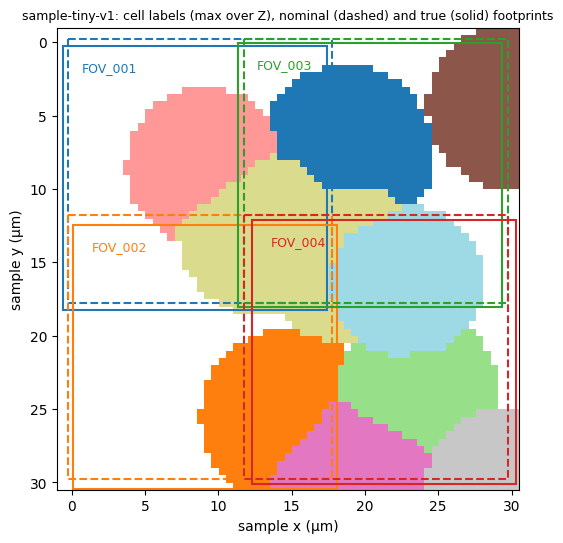

In [4]:
from starfinder.synthetic import SAMPLE_PRESET_VERSION, generate_sample_scene, sample_scene_preset, save_sample_scene

book, config = sample_scene_preset("sample-tiny-v1")
acquisition = config.acquisition
with timed("generate and save the sample scene (sample-tiny-v1, seed 42)"):
    scene = generate_sample_scene(book, config=config)
    SCENE = WORKSPACE / "scene"
    save_sample_scene(scene, SCENE)
SAMPLE, DATASET = scene.sample, config.fov.dataset_version
FOV_SHAPE, SPACING = acquisition.fov_shape_zyx, acquisition.spacing_zyx
ROUNDS = tuple(next(iter(scene.fovs.values())).round_labels)
print("preset version:", SAMPLE_PRESET_VERSION, " scene:", DATASET, " sample:", SAMPLE, " seed:", config.fov.seed)
print(f"grid: {acquisition.columns} x {acquisition.rows} FOVs ({acquisition.order}), overlap {acquisition.overlap:.4f}")
print("FOV shape (ZYX):", FOV_SHAPE, " spacing (µm):", SPACING, " jitter bound (voxels):", acquisition.jitter_max_zyx)
print("rounds:", {label: f"{image.shape} {image.dtype}" for label, image in next(iter(scene.fovs.values())).rounds.items()})
print("stain per FOV:", {fov: f"{image.shape} {image.dtype}" for fov, image in scene.stains.items()})
print("sample label grid:", scene.sample_labels["cell"].shape, " origin (µm):",
      tuple(round(v, 6) for v in scene.sample_grid.origin_zyx))
for name in ("cells", "molecules"):
    truth_table = getattr(scene, name)
    print(f"truth {name}: {int(truth_table.in_sample.sum())} in the sample, "
          f"{int((~truth_table.in_sample).sum())} in the halo")
print("saved:", len(files_under(SCENE)), "files; top level:", sorted(p.name for p in SCENE.iterdir()))

TRUTH = pd.read_csv(SCENE / "placement_truth.csv", float_precision="round_trip").set_index("fov_id")
display(TRUTH[["grid_column", "grid_row", "nominal_z", "nominal_y", "nominal_x", "true_origin_z", "true_origin_y",
               "true_origin_x", "jitter_z_vox", "jitter_y_vox", "jitter_x_vox"]])
print("Z jitter present:", bool((TRUTH.jitter_z_vox != 0).any()))


def footprint(origin_yx, shape_yx=FOV_SHAPE[1:], spacing_yx=SPACING[1:]):
    # The half-open sample-frame footprint [o - s/2, o + (n - 1/2) s) in Y and X, as a matplotlib rectangle.
    (oy, ox), (ny, nx), (sy, sx) = origin_yx, shape_yx, spacing_yx
    return (ox - sx / 2, oy - sy / 2), nx * sx, ny * sy


grid_meta = scene.sample_grid
labels_2d = scene.sample_labels["cell"].max(axis=0)
(gy, gx), (sy, sx) = grid_meta.origin_zyx[1:], grid_meta.spacing_zyx[1:]
extent = (gx - sx / 2, gx + (labels_2d.shape[1] - 0.5) * sx, gy + (labels_2d.shape[0] - 0.5) * sy, gy - sy / 2)
fig, ax = plt.subplots(figsize=(6, 6))
ax.imshow(np.ma.masked_equal(labels_2d, 0) % 20, cmap="tab20", extent=extent, interpolation="nearest")
for k, (fov, row) in enumerate(TRUTH.iterrows()):
    colour = f"C{k}"
    for (oy, ox), style in (((row.nominal_y, row.nominal_x), "--"), ((row.true_origin_y, row.true_origin_x), "-")):
        corner, width, height = footprint((oy, ox))
        ax.add_patch(plt.Rectangle(corner, width, height, fill=False, ec=colour, ls=style, lw=1.5))
    ax.text(row.true_origin_x + 1, row.true_origin_y + 1.5, fov, color=colour, fontsize=9)
ax.set_xlabel("sample x (µm)")
ax.set_ylabel("sample y (µm)")
ax.set_title("sample-tiny-v1: cell labels (max over Z), nominal (dashed) and true (solid) footprints", fontsize=9)
plt.show()

## 3. The tile position table

A placement starts from the FOVs' **nominal** positions, a `TilePositionTable` in µm
([docs/stitching-contract.md](../../docs/stitching-contract.md), "Tile position table"). One of
three converters builds it: `positions_from_leica` from a stage file (with an explicit
`StageAxisMapping`), `positions_from_grid` from a regular grid, or `positions_from_table` from
a CSV. The scene's `positions.csv` holds the nominal grid, read with `positions_from_table`.
Every nominal z is 0: one layer of tiles, which ownership needs (section 7).

Each FOV's **reference grid** (`ReferenceGrid`: its shape and `ImageMetadata`) gives its size
and spacing. Here the grids are declared from the scene's metadata, which records the spacing
in µm; section 5 checks that `FOV.run` gives the same grids. `neighbor_pairs` derives the pairs
whose nominal boxes overlap, diagonals included; a method registers those pairs.

In [5]:
from starfinder.segmentation import ReferenceGrid
from starfinder.stitching import neighbor_pairs, positions_from_table

table = positions_from_table(SCENE / "positions.csv")
FOV_IDS = list(table.fov_ids)
print("source:", clean(table.source), " unit:", table.unit, " converter:", table.record["converter"])
display(table.positions)
GRIDS = {fov: ReferenceGrid(FOV_SHAPE, scene.fov_metadata[fov], "declared") for fov in FOV_IDS}
print("grid of FOV_001:", GRIDS["FOV_001"].shape_zyx, GRIDS["FOV_001"].metadata)
pairs = neighbor_pairs(table, GRIDS)
print("neighbour pairs:", [(pair.fov_a, pair.fov_b) for pair in pairs])

source: table:<workspace>/scene/positions.csv  unit: µm  converter: positions_from_table


,fov_id,position_id,nominal_z,nominal_y,nominal_x,source,grid_column,grid_row
0,FOV_001,<NA>,0.0,0.0,0.0,supplied,<NA>,<NA>
1,FOV_002,<NA>,0.0,12.0,0.0,supplied,<NA>,<NA>
2,FOV_003,<NA>,0.0,0.0,12.0,supplied,<NA>,<NA>
3,FOV_004,<NA>,0.0,12.0,12.0,supplied,<NA>,<NA>


grid of FOV_001: (5, 36, 36) ImageMetadata(frame_id='["sample-tiny-v1","sample","FOV_001","formed"]/reference', spacing_zyx=(1.0, 0.5, 0.5), origin_zyx=(0.0, 0.0, 0.0), direction_zyx=((1.0, 0.0, 0.0), (0.0, 1.0, 0.0), (0.0, 0.0, 1.0)), spatial_unit='µm')
neighbour pairs: [('FOV_001', 'FOV_002'), ('FOV_001', 'FOV_003'), ('FOV_001', 'FOV_004'), ('FOV_002', 'FOV_003'), ('FOV_002', 'FOV_004'), ('FOV_003', 'FOV_004')]


## 4. A placement

### The truth, supplied through `placement_from_table`

A placement that is known rather than measured enters through
`placement_from_table(table, grids, sample=…, origins=…)`
([docs/stitching-contract.md](../../docs/stitching-contract.md), "Supplied placement"). With
`origins` it keeps each supplied origin as given (float64, never rounded) and sets each
correction to `origin − nominal`; every FOV is `metadata_only` with the flag `supplied`, and no
method runs. Here the origins are the scene's `true_origin_z/y/x`, so the corrections are the
`true_correction_*` of `placement_truth.csv`. The tiles keep the grid's one nominal z, so the
placement is **one layer**, which `assemble` accepts (check 8 of
[docs/assembly-contract.md](../../docs/assembly-contract.md), "Checks the entry applies"),
while the Z jitter moves each FOV's sample z.

**Review and approval.** A supplied placement is never trusted silently: its review is
`required` with the reason `supplied_placement`, whatever the positions. `assemble` and
`Dataset.export` refuse it (`PlacementReviewRequiredError`, check 2 of "Checks before anything
is written") until `approve_placement` records an approval: the reviewer, the UTC time, a note
and the SHA-256 of the FOV and link tables it approves. The approval changes no origin,
correction, status or flag. The cell checks each of these (the approval's time is a wall-clock
value and is printed as `<UTC time>`), then saves the approved placement with `save_placement`
into `stitching/<sample>/` of the dataset that section 5 builds (option S1), which
`Dataset.export` reads.

In [6]:
from starfinder.stitching import approve_placement, load_placement, placement_from_table, review_placement, save_placement

ORIGIN = ["origin_z", "origin_y", "origin_x"]
CORRECTION = ["correction_z", "correction_y", "correction_x"]
TRUE_ORIGIN = ["true_origin_z", "true_origin_y", "true_origin_x"]
TRUE_CORRECTION = ["true_correction_z", "true_correction_y", "true_correction_x"]
origins = {fov: tuple(TRUTH.loc[fov, TRUE_ORIGIN]) for fov in FOV_IDS}
supplied = placement_from_table(table, GRIDS, sample=SAMPLE, origins=origins)
display(supplied.fovs[["fov_id", "status", *ORIGIN, *CORRECTION, "component", "flags"]])
truth_rows = TRUTH.loc[FOV_IDS]
origin_equal = bool(np.array_equal(supplied.fovs[ORIGIN].to_numpy(), truth_rows[TRUE_ORIGIN].to_numpy()))
correction_error = np.abs(supplied.fovs[CORRECTION].to_numpy() - truth_rows[TRUE_CORRECTION].to_numpy()).max(axis=0)
print("origins equal true_origin_* exactly:", origin_equal)
print("largest |correction - true_correction| (µm, Z Y X):", correction_error.tolist())
print('record["origins"]:', supplied.record["origins"], ' method:', supplied.record["method"]["method"],
      ' gauge:', supplied.record["gauge"], ' frame:', supplied.record["frame"]["frame_id"])
review = review_placement(supplied).record["review"]
print("review:", review["state"], review["reasons"], " approvals:", review["approvals"])
print("statuses:", sorted(set(supplied.fovs.status)), " flags:", sorted(set(supplied.fovs["flags"])),
      " nominal z:", sorted(set(supplied.fovs.nominal_z)))
assert origin_equal and (correction_error <= 1e-9).all()
assert supplied.record["origins"] == "supplied"
assert review["state"] == "required" and review["reasons"] == ["supplied_placement"] and not review["approvals"]

OUTPUT = WORKSPACE / "data" / "output"
PLACEMENT_DIR = OUTPUT / "stitching" / SAMPLE
dataset_for_refusal = Dataset(WORKSPACE / "data" / "input", OUTPUT, DATASET, SAMPLE, "output")
print("\nexport before approval:", error_of(lambda: dataset_for_refusal.export(
    SAMPLE, placement=supplied, output_dir=OUTPUT / "export" / SAMPLE)))
print("export folder written:", (OUTPUT / "export").exists())

approved = approve_placement(supplied, reviewer="tour", note="sample-tiny-v1: the truth placement, supplied")
approval = approved.record["review"]["approvals"][0]
print("\napproval:", {k: ("<UTC time>" if k == "time_utc" else v[:12] + "…" if k.endswith("sha256") else v)
                      for k, v in approval.items()})
unchanged = bool(approved.fovs.equals(supplied.fovs) and approved.links.equals(supplied.links))
print("approval changed no row of the FOV and link tables:", unchanged,
      " review state still:", approved.record["review"]["state"], "(now with an approval)")
assert unchanged and np.array_equal(approved.fovs[ORIGIN].to_numpy(), truth_rows[TRUE_ORIGIN].to_numpy())

save_placement(approved, PLACEMENT_DIR)
reloaded = load_placement(PLACEMENT_DIR)
print("\nsaved:", clean(PLACEMENT_DIR), files_under(PLACEMENT_DIR))
print("reloaded FOV table equal:", reloaded.fovs.equals(approved.fovs), " approvals kept:",
      len(reloaded.record["review"]["approvals"]))

,fov_id,status,origin_z,origin_y,origin_x,correction_z,correction_y,correction_x,component,flags
0,FOV_001,metadata_only,-0.021128,0.479471,-0.308818,-0.021128,0.479471,-0.308818,0,supplied
1,FOV_002,metadata_only,0.322911,12.684024,0.380672,0.322911,0.684024,0.380672,1,supplied
2,FOV_003,metadata_only,0.050200,0.286808,11.621612,0.050200,0.286808,-0.378388,2,supplied
3,FOV_004,metadata_only,-0.072213,12.367896,12.562320,-0.072213,0.367896,0.562320,3,supplied


origins equal true_origin_* exactly: True
largest |correction - true_correction| (µm, Z Y X): [0.0, 0.0, 0.0]
record["origins"]: supplied  method: supplied  gauge: none  frame: sample:sample


review: required ['supplied_placement']  approvals: []
statuses: ['metadata_only']  flags: ['supplied']  nominal z: [0.0]

export before approval: PlacementReviewRequiredError: the placement of sample 'sample' needs review (supplied_placement) and holds no approval of its current tables; inspect it and call approve_placement(result, reviewer=..., note=...)
export folder written: False

approval: {'reviewer': 'tour', 'time_utc': '<UTC time>', 'note': 'sample-tiny-v1: the truth placement, supplied', 'fovs_sha256': '986f20b17367…', 'links_sha256': '779e40a251de…'}
approval changed no row of the FOV and link tables: True  review state still: required (now with an approval)

saved: <workspace>/data/output/stitching/sample ['fovs.csv', 'links.csv', 'placement.json']
reloaded FOV table equal: True  approvals kept: 1


### The same tiles through `multiview_stitcher`

`stitch(inputs, table, config=…)` runs a registered method on one image per FOV
(`StitchingInput`) and returns the same `PlacementResult`, with each FOV `image_supported`
(placed by registration), `metadata_only` (left at its nominal position) or `failed`, the
registered pairs in `links`, and the review policy applied
([docs/stitching-algorithms.md](../../docs/stitching-algorithms.md)).
`MultiviewStitcherConfig` selects `multiview_stitcher`, the second registered backend beside
BigStitcher, which runs in Fiji as an engine task and is not run here. The cell uses the
configuration of check MV3 of the validation design: the reference round's channel maximum,
`binning_zyx=(1, 1, 1)` and the link filter off (`quality_threshold=-1.0`; the default 0.7 is
unchanged and is a starting value for real tiles). A measured placement is fixed in gauge G1:
the whole placement may differ from the truth by one translation, so the cell compares its
origins with `true_origin_g1_*` of `placement_truth.csv`, the truth expressed in that gauge.

This is a demonstration on four tiles of 5 × 36 × 36 voxels, not a qualification of the
backend: the printed differences are a measurement, there is no tolerance, and the export of
section 6 uses the supplied truth. When the review is `required`, the cell approves it as the
caller would, after printing the reasons. The cell needs the `multiview-stitcher` extra.

In [7]:
from starfinder.stitching import MultiviewStitcherConfig, StitchingInput, stitch

if not EXTRAS["multiview-stitcher"]:
    skipped("the multiview-stitcher extra (starfinder[multiview-stitcher]) is not installed")
else:
    inputs = [StitchingInput(fov, scene.fovs[fov].rounds[ROUNDS[0]].max(axis=-1), GRIDS[fov], "reference_merged")
              for fov in FOV_IDS]
    with timed("stitch with multiview_stitcher (4 FOVs, binning 1)"), synchronous():
        stitched = stitch(inputs, table, sample=SAMPLE,
                          config=MultiviewStitcherConfig(binning_zyx=(1, 1, 1), quality_threshold=-1.0))
    print("method:", stitched.record["method"]["method"], " gauge:", stitched.record["gauge"])
    display(stitched.fovs[["fov_id", "status", *ORIGIN, *CORRECTION, "n_links_kept", "flags"]].round(6))
    display(stitched.links[["fov_a", "fov_b", "shift_z", "shift_y", "shift_x", "quality", "kept", "reason",
                            "residual"]].round(6))
    g1 = TRUTH.loc[FOV_IDS, ["true_origin_g1_z", "true_origin_g1_y", "true_origin_g1_x"]].to_numpy()
    difference = (stitched.fovs[ORIGIN].to_numpy() - g1) / np.asarray(SPACING)
    print("origin - true_origin_g1 (voxels, Z Y X; a measurement):")
    print(pd.DataFrame(difference, index=FOV_IDS, columns=["z", "y", "x"]).round(3))
    stitched_review = stitched.record["review"]
    print("review:", stitched_review["state"], stitched_review["reasons"], " policy:", stitched_review["policy"])
    if stitched_review["state"] == "required":
        stitched = approve_placement(stitched, reviewer="tour", note="multiview_stitcher on sample-tiny-v1")
        print("approved after review; approvals:", len(stitched.record["review"]["approvals"]))

method: multiview_stitcher  gauge: G1


,fov_id,status,origin_z,origin_y,origin_x,correction_z,correction_y,correction_x,n_links_kept,flags
0,FOV_001,image_supported,0.0,0.031249,-0.406245,0.0,0.031249,-0.406245,2,
1,FOV_002,image_supported,0.0,12.218750,0.406248,0.0,0.218750,0.406248,2,
2,FOV_003,image_supported,0.0,-0.156250,11.531248,0.0,-0.156250,-0.468752,2,
3,FOV_004,image_supported,0.0,11.906250,12.468748,0.0,-0.093750,0.468748,2,


,fov_a,fov_b,shift_z,shift_y,shift_x,quality,kept,reason,residual
0,FOV_001,FOV_002,-0.0,0.25,0.75,0.550848,True,,0.088383
1,FOV_001,FOV_003,-0.0,-0.25,-0.00,0.790446,True,,0.088394
2,FOV_001,FOV_004,NaN,NaN,NaN,NaN,False,pruned,NaN
3,FOV_002,FOV_003,NaN,NaN,NaN,NaN,False,pruned,NaN
4,FOV_002,FOV_004,-0.0,-0.25,-0.00,0.575951,True,,0.088388
5,FOV_003,FOV_004,-0.0,-0.00,1.00,0.550828,True,,0.088388


origin - true_origin_g1 (voxels, Z Y X; a measurement):
             z      y      x
FOV_001  0.091  0.013 -0.067
FOV_002 -0.253 -0.021  0.179
FOV_003  0.020  0.023 -0.053
FOV_004  0.142 -0.014 -0.059
review: not_needed []  policy: {'max_correction_fraction': 0.5, 'max_residual_um': 1.0}


## 5. The per-FOV §2.9 results through mask import

`Dataset.export` reads saved files only. Per FOV it needs, under the dataset's output root
([docs/sample-output-contract.md](../../docs/sample-output-contract.md), "The parts, in
order", and the docstring of `Dataset.export`):

* `images/ref_merged/<fov>.tif`, whose grid (`reference_grid_from_file`) is the FOV's
  reference grid; `FOV.save_reference_image` writes it;
* the §2.9 assignment folder `checkpoints/<fov>/assignment/<name>/`, which
  `FOV.assign(…, checkpoints=…)` writes;
* for the default fused image, the `reference_stain` saved under
  `checkpoints/<fov>/other_rounds/reference_stain/image.ome.tif`.

The cell runs, per FOV, the §2.9 path with **mask import**, so no segmenter runs:

1. `FOV.run` on the FOV's four rendered rounds: local maxima, extraction, the WTA decoder,
   the shared score and the default filter, as in the §2.8 tour. Two settings are choices for
   this demonstration, not recommendations: `exclude_border=False` keeps the molecules up to
   the FOV's edge, where ownership matters, and `negative_policy="clip_negative"` lets the
   decoder read the scene's `float32` rounds, whose read noise around 0 makes some extracted
   values negative;
2. `import_labels` of the FOV's truth labels `labels/cells.tif` and `labels/nuclei.tif` on the
   FOV's grid, with `relabel=False` so each cell keeps its sample cell ID;
3. `FOV.assign(cells=…, nuclei=…, checkpoints=…)`, which calls `assign_molecules` on the
   accepted reads and saves the result as the assignment `default`.

**One molecule key on both routes.** The route after fusion (section 17) reads each FOV's
goodSpots table `signal/<fov>_goodSpots.csv` through `molecule_table_from_csv`, which names the
row `i` `csv:<i>`. The workflow's per-FOV assignment reads the same table, so on a dataset
processed by the workflow a molecule has one key on both routes. `FOV.assign` reads `FOV.run`'s
reads instead, named by the detection's spot IDs (`0`, `1`, …), and `compare_routes` (section
18) needs one molecule population in both folders. So, after `FOV.run`, the cell writes the
goodSpots table with `FOV.save_spots` and names each accepted read by its row of that table,
`csv:<row>`, in the FOV's spot, decoding and filtering results, before `FOV.assign`; the reads
that were not accepted keep their IDs. It then checks, row by row, that the table read back
holds the same keys, positions and genes as the renamed reads.

The stain is already on each FOV's reference grid (the scene renders it with the reference
round), so the cell writes it with `save_volume` where `FOV.prepare_morphology` would save it;
`prepare_morphology` loads raw files from an input folder, which this synthetic sample does not
have. The molecules of the export are therefore the reads `FOV.run` accepted, not the scene's
truth molecules; section 9 also assembles the truth molecules, in memory, to compare with the
sample-level truth.

In [8]:
import dataclasses

from starfinder.assignment import molecule_table, molecule_table_from_csv, summarize_assignment
from starfinder.readout import NeighborhoodSumConfig, ReadFilterConfig, ReadScoreConfig, WtaDecoderConfig
from starfinder.dataset import CheckpointConfig, PipelineConfig, RoundState
from starfinder.io import save_volume
from starfinder.segmentation import import_labels
from starfinder.spot_finding import LocalMaximaConfig

dataset = Dataset(WORKSPACE / "data" / "input", OUTPUT, DATASET, SAMPLE, "output",
                  rounds=RoundState(sequencing_rounds=list(ROUNDS), reference_round=ROUNDS[0]),
                  channel_order=list(book.channel_labels))
dataset.codebook = book
CHECKPOINTS = CheckpointConfig(directory=OUTPUT / "checkpoints")
PIPELINE = PipelineConfig(spot_finding=LocalMaximaConfig(exclude_border=False), extraction=NeighborhoodSumConfig(),
                          decoding=WtaDecoderConfig(negative_policy="clip_negative"), scoring=ReadScoreConfig(),
                          filtering=ReadFilterConfig())
STAIN_FILE = Path("other_rounds") / "reference_stain" / "image.ome.tif"


def truth_labels(fov, grid, run):
    # The FOV's truth cell and nucleus labels through import_labels, keeping the sample IDs.
    namespace = json.dumps([DATASET, SAMPLE, fov, None, run], separators=(",", ":"))
    return {target: import_labels(SCENE / "fovs" / fov / "labels" / file, grid=grid, target=target, relabel=False,
                                  label_namespace=namespace)
            for target, file in (("cell", "cells.tif"), ("nucleus", "nuclei.tif"))}


def name_reads_by_row(fov, goodspots):
    # Name each accepted read csv:<row>, its row of the goodSpots table, as molecule_table_from_csv names it; then
    # check that the table read back holds the renamed reads row by row (keys, positions, genes).
    order = list(molecule_table(fov.spot_result, fov.filtering_result, genes=book.genes).table.spot_id)
    rename = {old: f"csv:{row}" for row, old in enumerate(order)}

    def renamed(frame):
        return frame.assign(spot_id=pd.array([rename.get(s, s) for s in frame.spot_id], dtype="string"))

    fov.spot_result = dataclasses.replace(fov.spot_result, spots=renamed(fov.spot_result.spots))
    fov.decoding_result = dataclasses.replace(fov.decoding_result, table=renamed(fov.decoding_result.table))
    fov.filtering_result = dataclasses.replace(fov.filtering_result, table=renamed(fov.filtering_result.table))
    reads = molecule_table(fov.spot_result, fov.filtering_result, genes=book.genes).table
    table_rows = molecule_table_from_csv(goodspots, spot_namespace=fov.spot_result.spot_namespace,
                                         genes=book.genes).table
    return (list(reads.spot_id) == list(table_rows.spot_id) and list(reads.gene_id) == list(table_rows.gene_id)
            and np.array_equal(reads[["z", "y", "x"]].to_numpy(np.float64),
                               table_rows[["z", "y", "x"]].to_numpy(np.float64)))


FOVS, rows = {}, []
with timed("per FOV: FOV.run, import_labels, FOV.assign with checkpoints (4 FOVs)"):
    for fov_id in FOV_IDS:
        fov = dataset.fov(fov_id)
        fov.images = {label: image.copy() for label, image in scene.fovs[fov_id].rounds.items()}
        fov.metadata = {label: scene.fov_metadata[fov_id] for label in ROUNDS}
        fov.run(PIPELINE)
        fov.save_reference_image()
        goodspots_ok = name_reads_by_row(fov, fov.save_spots())
        assert goodspots_ok
        grid = fov.reference_grid()
        assert grid.shape_zyx == GRIDS[fov_id].shape_zyx and grid.metadata == GRIDS[fov_id].metadata
        labels = truth_labels(fov_id, grid, "truth")
        fov.assign(cells=labels["cell"], nuclei=labels["nucleus"], checkpoints=CHECKPOINTS)
        save_volume(scene.stains[fov_id][..., None], CHECKPOINTS.directory / fov_id / STAIN_FILE,
                    metadata=scene.fov_metadata[fov_id])
        FOVS[fov_id] = fov
        result = fov.assignment_results["default"]
        summary = summarize_assignment(result)
        rows.append(dict(fov_id=fov_id, spots=len(fov.spot_result.spots), accepted_reads=len(result.molecules),
                         **{k: summary[k] for k in ("assigned", "unassigned", "excluded_cell", "outside_grid")},
                         cells=len(result.cells), cells_kept=int((result.cells.status == "kept").sum())))
display(pd.DataFrame(rows))
print("the grid of every FOV.run equals the declared grid: True")
print("the goodSpots table of every FOV holds its accepted reads, named csv:<row>, row by row: True")
print("files of FOV_001 under the output root:")
for path in files_under(OUTPUT):
    if "FOV_001" in path:
        print("  ", path)

,fov_id,spots,accepted_reads,assigned,unassigned,excluded_cell,outside_grid,cells,cells_kept
0,FOV_001,26,23,18,5,0,0,3,3
1,FOV_002,15,13,12,1,0,0,6,3
2,FOV_003,33,31,17,3,11,0,5,3
3,FOV_004,39,32,29,0,3,0,7,5


the grid of every FOV.run equals the declared grid: True
the goodSpots table of every FOV holds its accepted reads, named csv:<row>, row by row: True
files of FOV_001 under the output root:
   checkpoints/FOV_001/assignment/default/assignment.json
   checkpoints/FOV_001/assignment/default/cell_labels.tif
   checkpoints/FOV_001/assignment/default/cells.csv
   checkpoints/FOV_001/assignment/default/counts.csv
   checkpoints/FOV_001/assignment/default/molecules.csv
   checkpoints/FOV_001/assignment/default/nuclei.csv
   checkpoints/FOV_001/assignment/default/nucleus_labels.tif
   checkpoints/FOV_001/other_rounds/reference_stain/image.ome.tif
   images/ref_merged/FOV_001.tif
   signal/FOV_001_goodSpots.csv


## 6. `Dataset.export` and its parts

The call below is the whole sample-level export on the **route per FOV**: the approved
placement saved in section 4, the assignment `default` of every FOV, and `ExportConfig` at its
defaults with `route: per_fov` set and the two opt-in parts turned on (`fuse_labels=True`,
`export_spatialdata=True`), into `export/<sample>/`
([docs/sample-output-contract.md](../../docs/sample-output-contract.md), "The export entry").
The route is set because this dataset's fused image is the default projection, whose default
route is the route after fusion, and that route needs settings of its own (section 15 shows
the refusal without them; section 17 runs that route). Before anything is written the export
checks, in order, the configs, the placement's review, the extras the assemble part needs
(`anndata`), the assembly, the fusion inputs, the label IDs and the route (check 7); then it
runs the parts and writes `export.json` after each. The part `segment` of the route after
fusion is recorded `off` with the reason `route_per_fov`. A part that cannot run (an extra not
installed, a source file missing) is recorded `not_run` with an `ExportIncompleteWarning`, and
the files of the earlier parts are still written (section 14).

`check_export` then checks the folder against its record (R1 to R3 and the per-file checks of
"Read-back checks"): every listed file exists with its SHA-256, every file is listed, the
tables pass `load_assembly`, and each image file has the layout and geometry its section
records. Without `anndata` the assemble part cannot write `sample.h5ad`, so the entry raises
before writing anything; the cell then prints why and assembles in memory instead (sections 7
to 9 still run; sections 10 to 20 skip).

In [9]:
from starfinder.assembly import AssemblyInput, assemble, load_assembly
from starfinder.export import ExportIncompleteWarning, check_export

EXPORT = OUTPUT / "export" / SAMPLE
CONFIG = ExportConfig(route="per_fov", fuse_labels=True, export_spatialdata=True)
EXPORTED = False
if not EXTRAS["anndata"]:
    skipped("the anndata extra (starfinder[anndata]) is not installed, so Dataset.export refuses the assemble part: "
            + error_of(lambda: dataset.export(SAMPLE, placement=PLACEMENT_DIR, config=CONFIG, output_dir=EXPORT)))
    assembly_inputs = [AssemblyInput(f, FOVS[f].reference_grid(),
                                     assignment=CHECKPOINTS.directory / f / "assignment" / "default") for f in FOV_IDS]
    assembly = assemble(approved, assembly_inputs)
    print("assembled in memory from the same saved assignment folders instead")
else:
    with timed("Dataset.export: assemble, fuse, fuse_labels, export_spatialdata"), synchronous(), \
            warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always", ExportIncompleteWarning)
        record = dataset.export(SAMPLE, placement=PLACEMENT_DIR, config=CONFIG, output_dir=EXPORT)
    for warning in caught:
        if issubclass(warning.category, ExportIncompleteWarning):
            print(f"{warning.category.__name__}: {clean(warning.message)}")
    EXPORTED = True
    print("folder:", clean(record.folder))
    print("parts:", record.parts, " complete:", record.complete)
    print("route:", record.record["assembly"]["route"], f"({record.record['assembly']['route_source']})",
          " segment:", record.record["segmentation"]["status"], f"({record.record['segmentation']['reason']})")
    print("files:", [p for p in files_under(EXPORT) if not p.startswith("sample.zarr/")],
          "and sample.zarr/" if (EXPORT / "sample.zarr").exists() else "")
    print("export.json sections:", [k for k in record.record if k in ("assembly", "fusion", "labels", "spatialdata")])
    check_export(EXPORT)
    print("check_export: passed")
    assembly = load_assembly(EXPORT)
print("\nsample tables:", {name: getattr(assembly, name).shape for name in ("fovs", "cells", "molecules", "counts")})
display(assembly.fovs[["fov_id", "placement_status", "origin_z", "origin_y", "origin_x", "owns_points", "n_cells",
                       "n_cells_retained", "n_molecules", "n_molecules_retained"]])

folder: <workspace>/data/output/export/sample
parts: {'assemble': 'written', 'fuse': 'written', 'segment': 'off', 'fuse_labels': 'written', 'export_spatialdata': 'written'}  complete: True
route: per_fov (set)  segment: off (route_per_fov)
files: ['cell_labels.ome.tif', 'export.json', 'reference_stain_projection.ome.tif', 'sample.h5ad', 'tables/cells.csv', 'tables/counts.csv', 'tables/fovs.csv', 'tables/molecules.csv'] and sample.zarr/
export.json sections: ['assembly', 'fusion', 'labels', 'spatialdata']


check_export: passed

sample tables: {'fovs': (4, 17), 'cells': (21, 37), 'molecules': (99, 24), 'counts': (86, 6)}


,fov_id,placement_status,origin_z,origin_y,origin_x,owns_points,n_cells,n_cells_retained,n_molecules,n_molecules_retained
0,FOV_001,metadata_only,-0.021128,0.479471,-0.308818,True,3,1,23,14
1,FOV_002,metadata_only,0.322911,12.684024,0.380672,True,6,0,13,1
2,FOV_003,metadata_only,0.050200,0.286808,11.621612,True,5,3,31,17
3,FOV_004,metadata_only,-0.072213,12.367896,12.562320,True,7,5,32,27


## 7. Ownership regions

Assembly decides which FOV owns each point of the sample from the placement alone
([docs/assembly-contract.md](../../docs/assembly-contract.md), "Ownership regions"): each
owning FOV has its footprint, the half-open box `[o − s/2, o + (n − ½)·s)` in Y and X, and a
point belongs to the FOV, among those whose footprint contains it, whose footprint **centre**
is nearest (O1, `ownership="nearest_center"`), ties going to the earlier FOV in table order.
Ownership is decided in Y and X only (option Z1): z is carried into the sample coordinates but
never decides ownership, which is why one layer is required. `ownership_map` returns the
geometry and a point test, `owner(points_zyx)`.

The cell prints the geometry, recomputes the rule by hand from the origins and grid sizes and
compares it with `owner` at every molecule's sample position, and checks that the sample
molecule table's `owner_fov_id` is that owner. The figure shows the regions with the molecules
marked by their assembly status.

,fov_id,placement_status,footprint_y0,footprint_y1,footprint_x0,footprint_x1,centre_y,centre_x,owns_points
0,FOV_001,metadata_only,0.229471,18.229471,-0.558818,17.441182,9.229471,8.441182,True
1,FOV_002,metadata_only,12.434024,30.434024,0.130672,18.130672,21.434024,9.130672,True
2,FOV_003,metadata_only,0.036808,18.036808,11.371612,29.371612,9.036808,20.371612,True
3,FOV_004,metadata_only,12.117896,30.117896,12.312320,30.312320,21.117896,21.312320,True


molecules: 99  owner() equals the hand rule: True  equals owner_fov_id: True
molecules by their FOV (rows) and the owner of their position (columns):


owner,FOV_001,FOV_002,FOV_003,FOV_004
fov_id,,,,
FOV_001,16,2,5,0
FOV_002,2,5,2,4
FOV_003,8,2,17,4
FOV_004,0,3,3,26


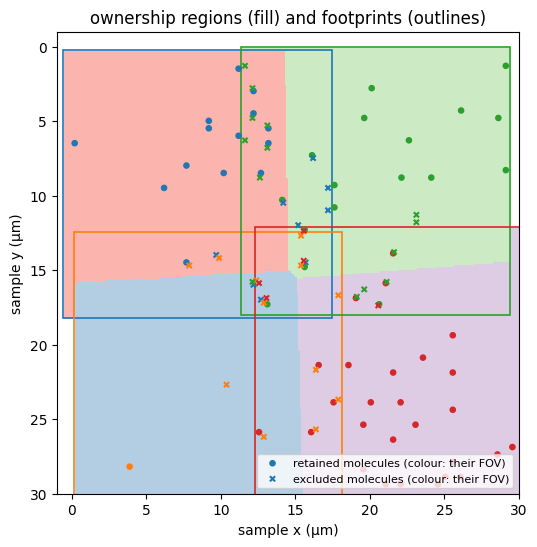

In [10]:
from starfinder.assembly import AssemblyConfig, ownership_map

regions = ownership_map(approved, GRIDS, config=AssemblyConfig())
display(regions.geometry[["fov_id", "placement_status", "footprint_y0", "footprint_y1", "footprint_x0", "footprint_x1",
                          "centre_y", "centre_x", "owns_points"]].round(6))


def owner_by_hand(points_yx, placement=approved):
    # Nearest footprint centre among the FOVs whose half-open footprint holds the point; ties by table order.
    (_, ny, nx), (_, sy, sx) = FOV_SHAPE, SPACING
    owners = []
    for y, x in points_yx:
        best, best_d = None, None
        for r in placement.fovs.itertuples():
            if r.origin_y - sy / 2 <= y < r.origin_y + (ny - 0.5) * sy and \
                    r.origin_x - sx / 2 <= x < r.origin_x + (nx - 0.5) * sx:
                d = (y - (r.origin_y + (ny - 1) / 2 * sy)) ** 2 + (x - (r.origin_x + (nx - 1) / 2 * sx)) ** 2
                if best_d is None or d < best_d:
                    best, best_d = r.fov_id, d
        owners.append(best)
    return owners


mols = assembly.molecules
points = mols[["sample_z", "sample_y", "sample_x"]].to_numpy(np.float64)
by_map = [None if pd.isna(o) else o for o in regions.owner(points)]
by_hand = owner_by_hand(points[:, 1:])
in_table = [None if pd.isna(o) else o for o in mols.owner_fov_id]
print("molecules:", len(mols), " owner() equals the hand rule:", by_map == by_hand,
      " equals owner_fov_id:", by_map == in_table)
print("molecules by their FOV (rows) and the owner of their position (columns):")
display(pd.crosstab(mols.fov_id.astype(object), pd.Series(by_map, name="owner", index=mols.index)))
assert by_map == by_hand == in_table

fig, ax = plt.subplots(figsize=(6, 6))
ys = np.linspace(-1, 30, 311)
xs = np.linspace(-1, 30, 311)
yy, xx = np.meshgrid(ys, xs, indexing="ij")
grid_owner = regions.owner(np.column_stack([np.zeros(yy.size), yy.ravel(), xx.ravel()]))
index = {fov: k for k, fov in enumerate(FOV_IDS)}
image = np.array([np.nan if pd.isna(o) else index[o] for o in grid_owner], float).reshape(yy.shape)
ax.imshow(image, cmap="Pastel1", vmin=0, vmax=8, extent=(xs[0], xs[-1], ys[-1], ys[0]), interpolation="nearest")
for k, r in enumerate(approved.fovs.itertuples()):
    corner, width, height = footprint((r.origin_y, r.origin_x))
    ax.add_patch(plt.Rectangle(corner, width, height, fill=False, ec=f"C{k}", lw=1.2))
for status, marker in (("retained", "o"), ("excluded", "x")):
    chosen = mols[mols.assembly_status == status]
    ax.scatter(chosen.sample_x, chosen.sample_y, s=14, marker=marker, c=[f"C{index[f]}" for f in chosen.fov_id],
               label=f"{status} molecules (colour: their FOV)")
ax.set_xlim(xs[0], xs[-1])
ax.set_ylim(ys[-1], ys[0])
ax.set_xlabel("sample x (µm)")
ax.set_ylabel("sample y (µm)")
ax.set_title("ownership regions (fill) and footprints (outlines)")
ax.legend(loc="lower right", fontsize=8)
plt.show()

## 8. Statuses, reasons and flags

Every cell and every molecule of every input FOV gets exactly one assembly status, `retained`
or `excluded`, with a reason when excluded
([docs/assembly-contract.md](../../docs/assembly-contract.md), "Retention", "Statuses and
reasons"). A cell is retained when the owner of its **ownership centroid** (the territory's
centroid in sample coordinates) is its own FOV, else excluded `not_owner`. Of two retained
cells of different FOVs whose territories share at least half of the smaller one, the larger
stays and the other is excluded `duplicate_observation`, naming the kept cell in
`duplicate_of` (the duplicate rule, decided on 2026-10-09; section 16). An assigned molecule
follows its cell (`cell_not_owner` or `cell_duplicate_observation` when the cell is excluded),
wherever it lies; an unassigned molecule is retained by its own position (`not_owner`
otherwise); an `outside_grid` molecule is excluded; a FOV without an origin excludes
everything (`fov_not_placed`). Excluded rows stay in the tables with their coordinates and
reasons.

**Flags** make visible what assembly cannot decide, and never change a status: `fov_edge`
and `z_edge` (a territory touching its grid's border), `conflict` (two retained cells of
different FOVs whose centroids fall in each other's territory: perhaps one biological cell
retained twice; a cell the duplicate rule excludes is no longer retained, so its pair raises no
`conflict`), `unclaimed` (an excluded cell no FOV retains there), `outside_owner_region` (a
retained molecule of a retained cell lying in another FOV's region, which may retain it as
unassigned) and `cell_unclaimed`. No merging repairs them; that is the agreed behaviour of
retention without cross-FOV merging. Section 19 returns to the flags on both routes.

In [11]:
from starfinder.assembly import (ASSEMBLY_STATUSES, CELL_ASSEMBLY_FLAGS, CELL_ASSEMBLY_REASONS, MOLECULE_ASSEMBLY_FLAGS,
                                 MOLECULE_ASSEMBLY_REASONS)

print("statuses:", ASSEMBLY_STATUSES)
print("cell reasons:", CELL_ASSEMBLY_REASONS, " molecule reasons:", MOLECULE_ASSEMBLY_REASONS)
print("cell flags:", CELL_ASSEMBLY_FLAGS, " molecule flags:", MOLECULE_ASSEMBLY_FLAGS)
cells = assembly.cells
for name, frame in (("cells", cells), ("molecules", mols)):
    reason = frame.assembly_reason.astype(object).where(frame.assembly_reason.notna(), "-")
    print(f"\n{name}: status (rows) by reason (columns)")
    display(pd.crosstab(frame.assembly_status.astype(object), reason))
print('record["counts"]:', json.dumps(assembly.record["counts"]))
print("\ncells with the flag conflict:")
display(cells[cells.assembly_flags.str.contains("conflict")][
    ["obs_name", "fov_id", "cell_id", "status", "assembly_status", "assembly_reason", "owner_fov_id",
     "sample_ownership_centroid_y", "sample_ownership_centroid_x", "assembly_flags", "conflict_with"]].round(3))

statuses: ('retained', 'excluded')
cell reasons: ('not_owner', 'fov_not_placed', 'duplicate_observation')  molecule reasons: ('cell_not_owner', 'not_owner', 'outside_grid', 'fov_not_placed', 'cell_duplicate_observation')
cell flags: ('fov_edge', 'z_edge', 'conflict', 'unclaimed')  molecule flags: ('outside_owner_region', 'cell_unclaimed')

cells: status (rows) by reason (columns)


assembly_reason,-,duplicate_observation,not_owner
assembly_status,,,
excluded,0,3,9
retained,9,0,0



molecules: status (rows) by reason (columns)

assembly_reason,-,cell_duplicate_observation,cell_not_owner,not_owner
assembly_status,,,,
excluded,0,17,19,4
retained,59,0,0,0


record["counts"]: {"cells": {"input": 21, "retained": 9, "excluded": {"not_owner": 9, "fov_not_placed": 0, "duplicate_observation": 3}}, "molecules": {"input": 99, "retained": 59, "excluded": {"cell_not_owner": 19, "not_owner": 4, "outside_grid": 0, "fov_not_placed": 0, "cell_duplicate_observation": 17}}, "flags": {"fov_edge": 18, "z_edge": 21, "conflict": 0, "unclaimed": 0, "outside_owner_region": 5, "cell_unclaimed": 0}}

cells with the flag conflict:


,obs_name,fov_id,cell_id,status,assembly_status,assembly_reason,owner_fov_id,sample_ownership_centroid_y,sample_ownership_centroid_x,assembly_flags,conflict_with


## 9. The count identities

Assembly loses no observation and invents none. With the input FOVs' cell and molecule tables
`C_f` and `M_f`, five identities hold exactly
([docs/assembly-contract.md](../../docs/assembly-contract.md), "Count accounting"):

1. **one assembly status each**: every input cell and molecule appears exactly once, keyed by
   `(cell_namespace, cell_id)` and `(spot_namespace, spot_id)`;
2. **the populations sum to the inputs**, in total and per FOV, and `record["counts"]` holds
   the totals (with the reasons of the duplicate rule when the rule is on); a cell excluded
   `duplicate_observation`, and only such a cell, names in `duplicate_of` a retained cell of
   another FOV;
3. **molecules follow their cell**, the one their own cell key `(cell_namespace, cell_id)`
   names (`cell_not_owner` or `cell_duplicate_observation` when it is excluded `not_owner` or
   `duplicate_observation`); an unassigned molecule is retained exactly when its position's
   owner is its FOV; an `outside_grid` molecule is excluded;
4. **the counted cells' counts equal the per-FOV counts** (counted: retained and §2.9 `kept`),
   so `Σ counts(whole) = #retained assigned molecules = Σ n_molecules over counted cells`;
5. **the §2.9 identities carry over**: `whole = nucleus + cytoplasm` per counted cell whose
   compartments are `available`, no compartment rows for the others, and the per-molecule
   compartment identity over the retained assigned molecules.

`AssemblyResult` checks them when it is built. The cell recomputes them here from the inputs,
independently, on the export's assembly against each FOV's §2.9 result. The export has the
duplicate rule on, at its default 0.5. Two parts of the recomputation follow changes of the
package after this notebook was first written: the reasons and `duplicate_of` of the duplicate
rule (W-400), and the cell key in the sample molecule table, `cell_namespace` (choice CK1 of
[docs/sample-segmentation-contract.md](../../docs/sample-segmentation-contract.md)).

In [12]:
def none(value):
    return None if pd.isna(value) else value


# The molecule reason that follows each cell reason (identity 3).
MOLECULE_REASON_OF_CELL = {"not_owner": "cell_not_owner", "duplicate_observation": "cell_duplicate_observation"}


def check_identities(result, inputs):
    # Identities 1 to 5 of "Count accounting", recomputed from the per-FOV AssignmentResults.
    cells, mols, counts = result.cells, result.molecules, result.counts
    checks = {}
    in_cells = [(r.cell_namespace, int(c)) for r in inputs.values() for c in r.cells.cell_id]
    in_mols = [k for r in inputs.values() for k in zip(r.molecules.spot_namespace, r.molecules.spot_id)]
    out_cells = list(zip(cells.cell_namespace, cells.cell_id.astype(int)))
    out_mols = list(zip(mols.spot_namespace, mols.spot_id))
    checks["1. one assembly status each"] = (
        sorted(out_cells) == sorted(in_cells) and len(set(out_cells)) == len(out_cells)
        and sorted(out_mols) == sorted(in_mols) and len(set(out_mols)) == len(out_mols)
        and set(cells.assembly_status) | set(mols.assembly_status) <= set(ASSEMBLY_STATUSES))
    sums = []
    for fov, given in inputs.items():
        for frame, n in ((cells, len(given.cells)), (mols, len(given.molecules))):
            rows = frame[frame.fov_id == fov]
            excluded = rows[rows.assembly_status == "excluded"].assembly_reason.value_counts()
            sums.append(n == len(rows) == int((rows.assembly_status == "retained").sum()) + int(excluded.sum()))
    recorded = result.record["counts"]
    # The reasons of the duplicate rule are counted when the rule is on.
    rule_on = result.record["config"]["duplicate_threshold"] is not None
    for name, frame, reasons in (("cells", cells, CELL_ASSEMBLY_REASONS), ("molecules", mols, MOLECULE_ASSEMBLY_REASONS)):
        excluded = frame[frame.assembly_status == "excluded"]
        reasons = [r for r in reasons if rule_on or not r.endswith("duplicate_observation")]
        sums.append(recorded[name] == {"input": len(frame), "retained": int((frame.assembly_status == "retained").sum()),
                                       "excluded": {r: int((excluded.assembly_reason == r).sum()) for r in reasons}})
        sums.append(set(excluded.assembly_reason.astype(object)) <= set(reasons))
    duplicate = (cells.assembly_reason.astype(object) == "duplicate_observation").to_numpy()
    retained_fov = cells[cells.assembly_status == "retained"].set_index("obs_name").fov_id.astype(object)
    sums.append(bool((cells.duplicate_of.notna().to_numpy() == duplicate).all()) and all(
        retained_fov.get(r.duplicate_of) not in (None, r.fov_id) for r in cells[duplicate].itertuples()))
    checks["2. the populations sum to the inputs"] = all(sums)
    cell_of = {(r.cell_namespace, int(r.cell_id)): (r.assembly_status, none(r.assembly_reason))
               for r in cells.itertuples()}
    follow = []
    for r in mols.itertuples():
        status, reason, assigned = r.assembly_status, none(r.assembly_reason), none(r.assignment_status)
        if assigned in ("assigned", "excluded_cell"):
            cell_status, cell_reason = cell_of[(r.cell_namespace, int(r.cell_id))]
            follow.append(status == cell_status and reason == (None if cell_status == "retained" else
                                                               MOLECULE_REASON_OF_CELL.get(cell_reason, cell_reason)))
        elif assigned == "outside_grid":
            follow.append((status, reason) == ("excluded", "outside_grid"))
        else:
            follow.append((status == "retained") == (none(r.owner_fov_id) == r.fov_id))
    checks["3. molecules follow their cell"] = all(follow)
    counted = cells[(cells.assembly_status == "retained") & (cells.status == "kept")]
    keys = {(r.fov_id, int(r.cell_id)) for r in counted.itertuples()}
    expected = sorted((fov, int(r.cell_id), r.gene_id, r.compartment, int(r.count))
                      for fov, given in inputs.items() for r in given.counts.itertuples()
                      if (fov, int(r.cell_id)) in keys)
    got = sorted((r.fov_id, int(r.cell_id), r.gene_id, r.compartment, int(r.count)) for r in counts.itertuples())
    whole = sum(n for *_, compartment, n in got if compartment == "whole")
    retained_assigned = mols[(mols.assignment_status == "assigned") & (mols.assembly_status == "retained")]
    checks["4. counted cells' counts equal the per-FOV counts"] = (
        got == expected and whole == len(retained_assigned) == int(counted.n_molecules.sum()))
    state = {(r.fov_id, int(r.cell_id)): r.compartments for r in counted.itertuples()}
    split, held = {}, {}
    for fov, cell, gene, compartment, n in got:
        if compartment != "whole":
            split[(fov, cell, gene)] = split.get((fov, cell, gene), 0) + n
    whole_available = {(f, c, g): n for f, c, g, comp, n in got if comp == "whole" and state[(f, c)] == "available"}
    no_rows = all(comp == "whole" or state[(f, c)] == "available" for f, c, g, comp, n in got)
    per_molecule = True
    for r in retained_assigned.itertuples():
        cell_state = state.get((r.fov_id, int(r.cell_id)))
        if cell_state is None:            # a retained assigned molecule's cell must be counted
            per_molecule = False
            continue
        allowed = ("nucleus", "cytoplasm") if cell_state == "available" else (cell_state,)
        per_molecule &= r.compartment in allowed
        if r.compartment in ("nucleus", "cytoplasm"):
            key = (r.fov_id, int(r.cell_id), r.gene_id, r.compartment)
            held[key] = held.get(key, 0) + 1
    checks["5. the §2.9 identities carry over"] = (
        split == whole_available and no_rows and per_molecule
        and held == {(f, c, g, comp): n for f, c, g, comp, n in got if comp != "whole"})
    return checks


export_inputs = {f: FOVS[f].assignment_results["default"] for f in FOV_IDS}
identities = check_identities(assembly, export_inputs)
print("duplicate_threshold of the export:", assembly.record["config"]["duplicate_threshold"])
for name, holds in identities.items():
    print(f"{name}: {holds}")
counted = cells[(cells.assembly_status == "retained") & (cells.status == "kept")]
print("\ninput cells", len(cells), "= retained", int((cells.assembly_status == "retained").sum()), "+ excluded",
      int((cells.assembly_status == "excluded").sum()), "; counted cells", len(counted))
print("Σ counts(whole) =", int(assembly.counts[assembly.counts.compartment == "whole"]["count"].sum()),
      "= retained assigned molecules =",
      int(((mols.assignment_status == "assigned") & (mols.assembly_status == "retained")).sum()),
      "= Σ n_molecules of counted cells =", int(counted.n_molecules.sum()))
assert all(identities.values())

duplicate_threshold of the export: 0.5
1. one assembly status each: True
2. the populations sum to the inputs: True
3. molecules follow their cell: True
4. counted cells' counts equal the per-FOV counts: True
5. the §2.9 identities carry over: True

input cells 21 = retained 9 + excluded 12 ; counted cells 8
Σ counts(whole) = 51 = retained assigned molecules = 51 = Σ n_molecules of counted cells = 51


### Against the sample-level truth (EE3 and EE4)

The export's molecules are the reads `FOV.run` found, which carry no link to the scene's truth
molecules. The validation design compares assembly with the sample-level truth on the path
that needs no segmenter and no detector
([docs/synthetic-sample-scene.md](../../docs/synthetic-sample-scene.md), "The path that needs
no segmenter"; [docs/stitching-assembly-validation.md](../../docs/stitching-assembly-validation.md),
EE2 to EE5): per FOV, the same truth labels through `import_labels(…, relabel=False)`, the
FOV's truth molecules `fovs/<fov>/molecules.csv` through `molecule_table_from_csv` (spot IDs
`csv:<row>`, which map to the scene's `amplicon_id`), `assign_molecules` without expansion, and
`assemble` on the same approved placement, in memory. The cell runs it, checks identities 1 to
5 on it (EE3), and asserts the four guarantees of EE4 against the truth tables, exactly:

* (a) every sample molecule (`in_sample`) has at least one copy that is not `outside_grid`;
* (b) every sample molecule whose copy in the FOV owning its sample position samples the label
  0 has exactly one retained `unassigned` copy, in that FOV;
* (c) a molecule with `r ≥ 2` retained copies has at least `r − 1` of them flagged
  `outside_owner_region`;
* (d) a retained `assigned` copy's `cell_id` differs from its `true_cell_id` exactly when the
  copy's `label_agrees` is false.

Duplicates and losses at the borders are the agreed behaviour of retention without matching.
The duplicate rule, on here at its default, adds losses of its own: the molecules of an
observation it excludes are excluded with it and are not given to the kept cell (section 16),
so a molecule whose only retained copy was in that observation has none. The cell prints how many
sample molecules have 0, 1 or 2 or more retained copies, as a count, not an accuracy.

In [13]:
from starfinder.assignment import assign_molecules, molecule_table_from_csv

with timed("the truth path in memory: assign_molecules and assemble"):
    truth_results = {}
    for fov_id in FOV_IDS:
        labels = truth_labels(fov_id, GRIDS[fov_id], "truth")
        molecules = molecule_table_from_csv(SCENE / "fovs" / fov_id / "molecules.csv",
                                            spot_namespace=json.dumps([DATASET, SAMPLE, fov_id, None],
                                                                      separators=(",", ":")),
                                            genes=book.genes)
        truth_results[fov_id] = assign_molecules(molecules, labels["cell"], grid=GRIDS[fov_id], nuclei=labels["nucleus"])
    truth_assembly = assemble(approved, [AssemblyInput(f, GRIDS[f], assignment=truth_results[f]) for f in FOV_IDS])
print("truth path:", {name: len(getattr(truth_assembly, name)) for name in ("cells", "molecules", "counts")})
ee3 = check_identities(truth_assembly, truth_results)
print("EE3, identities 1 to 5:", ee3)

copies = pd.read_csv(SCENE / "molecule_fovs.csv")
truth_molecules = pd.read_csv(SCENE / "molecules.csv").set_index("amplicon_id")
by_key = {(r.fov_id, int(r.spot_id.split(":")[1])): r for r in truth_assembly.molecules.itertuples()}
copy_rows = [by_key[(r.fov_id, int(r.csv_row))] for r in copies.itertuples()]
copies["status"] = [r.assembly_status for r in copy_rows]
copies["assignment"] = [r.assignment_status for r in copy_rows]
copies["cell"] = [none(r.cell_id) for r in copy_rows]
copies["assembly_flags"] = [r.assembly_flags for r in copy_rows]
groups = dict(tuple(copies.groupby("amplicon_id")))
sample_molecules = truth_molecules[truth_molecules.in_sample]
a = b = c = d = True
for amplicon, m in sample_molecules.iterrows():
    group = groups[amplicon]
    a &= bool((group.assignment != "outside_grid").any())
    owner = owner_by_hand([(m.sample_y, m.sample_x)])[0]
    own = group[group.fov_id == owner]
    if len(own) and own.fov_cell_label.iloc[0] == 0:
        b &= list(group[(group.status == "retained") & (group.assignment == "unassigned")].fov_id) == [owner]
for amplicon, group in groups.items():
    retained = group[group.status == "retained"]
    if len(retained) >= 2:
        c &= int(retained.assembly_flags.str.contains("outside_owner_region").sum()) >= len(retained) - 1
    true_cell = truth_molecules.loc[amplicon, "true_cell_id"]
    for r in retained[retained.assignment == "assigned"].itertuples():
        d &= (int(r.cell) != (0 if pd.isna(true_cell) else int(true_cell))) == (not r.label_agrees)
print("EE4 (a) a copy not outside_grid:", a, " (b) one retained unassigned copy in the owner:", b,
      " (c) r - 1 copies flagged:", c, " (d) cell_id differs exactly when label_agrees is false:", d)
retained_copies = copies[copies.status == "retained"].groupby("amplicon_id").size()
per_molecule = retained_copies.reindex(sample_molecules.index, fill_value=0).clip(upper=2)
print("sample molecules by retained copies (0, 1, 2 or more):",
      {("2+" if k == 2 else str(k)): int(v) for k, v in per_molecule.value_counts().sort_index().items()})
assert all(ee3.values()) and a and b and c and d

truth path: {'cells': 21, 'molecules': 144, 'counts': 88}
EE3, identities 1 to 5: {'1. one assembly status each': True, '2. the populations sum to the inputs': True, '3. molecules follow their cell': True, "4. counted cells' counts equal the per-FOV counts": True, '5. the §2.9 identities carry over': True}


EE4 (a) a copy not outside_grid: True  (b) one retained unassigned copy in the owner: True  (c) r - 1 copies flagged: True  (d) cell_id differs exactly when label_agrees is false: True
sample molecules by retained copies (0, 1, 2 or more): {'0': 4, '1': 48}


## 10. `sample.h5ad`

The assemble part writes `sample.h5ad` with `sample_anndata`
([docs/assembly-contract.md](../../docs/assembly-contract.md), "Sample-level AnnData"): one row
per **counted** cell, named by `obs_name` (`<sample>_<fov_id>_<cell_id>`), in the cell table's
order; `X` the whole-cell counts in the gene order of the record; the `nucleus` and
`cytoplasm` layers when nuclei were given; and `obsm["spatial"]` the ownership centroid
`[sample_ownership_centroid_x, sample_ownership_centroid_y]` in µm, the point that decided
retention. The cell reads it back and checks it against the sample tables exactly.

In [14]:
if not EXPORTED:
    skipped("the anndata extra (starfinder[anndata]) is not installed: no sample.h5ad was written")
else:
    import anndata

    adata = anndata.read_h5ad(EXPORT / "sample.h5ad")
    print(adata)
    n_obs_ok = adata.n_obs == len(counted)
    names_ok = list(adata.obs_names) == list(counted.obs_name)
    spatial = np.asarray(adata.obsm["spatial"])
    spatial_ok = bool(np.array_equal(spatial, counted[["sample_ownership_centroid_x",
                                                       "sample_ownership_centroid_y"]].to_numpy(np.float64)))
    whole = assembly.counts[assembly.counts.compartment == "whole"]
    x_total_ok = float(np.asarray(adata.X).sum()) == float(whole["count"].sum())
    print("n_obs:", adata.n_obs, " counted cells:", len(counted), " equal:", n_obs_ok)
    print("obs_names equal the counted cells' obs_name, in order:", names_ok)
    print('obsm["spatial"] equals [sample_ownership_centroid_x, sample_ownership_centroid_y] exactly:', spatial_ok)
    print("Σ X equals Σ counts(whole):", x_total_ok, " layers:", list(adata.layers), " genes:", adata.n_vars)
    print('uns["spatial_unit"]:', adata.uns["spatial_unit"], ' uns["frame_id"]:', adata.uns["frame_id"])
    assert n_obs_ok and names_ok and spatial_ok and x_total_ok

AnnData object with n_obs × n_vars = 8 × 16
    obs: 'sample', 'fov_id', 'cell_namespace', 'cell_id', 'size_voxels', 'expanded_size_voxels', 'size_physical', 'centroid_z', 'centroid_y', 'centroid_x', 'n_molecules', 'n_nuclei', 'correspondence', 'correspondence_flags', 'compartments', 'sample_centroid_z', 'sample_centroid_y', 'sample_centroid_x', 'sample_expanded_centroid_z', 'sample_expanded_centroid_y', 'sample_expanded_centroid_x', 'ownership_centroid', 'sample_ownership_centroid_z', 'sample_ownership_centroid_y', 'sample_ownership_centroid_x', 'assembly_flags', 'conflict_with'
    uns: 'assembly', 'frame_id', 'spatial_centroid', 'spatial_unit'
    obsm: 'spatial'
    layers: 'cytoplasm', 'nucleus'
n_obs: 8  counted cells: 8  equal: True
obs_names equal the counted cells' obs_name, in order: True
obsm["spatial"] equals [sample_ownership_centroid_x, sample_ownership_centroid_y] exactly: True
Σ X equals Σ counts(whole): True  layers: ['cytoplasm', 'nucleus']  genes: 16
uns["spatial_uni

## 11. The default fused projection and its geometry

The fuse part makes one image of the sample with multiview-stitcher's `fuse`, from the
placement of either backend, with the library's own blending
([docs/sample-output-contract.md](../../docs/sample-output-contract.md), "The fused image").
By default it fuses the `reference_stain` as the **2D maximum projection at scale 0.5**: the
library's `level1` route averages each FOV in 2 × 2 blocks in Y and X (Z is never reduced),
fuses them, and Starfinder writes the result as an OME-TIFF. A dataset of dense 3D tissue sets
`dimensionality: stack` instead.

**Geometry.** The fusion grid is the union grid of the included FOVs: spacing `s`, origin
`o_a = min_f origin_f,a`, and `n0_a = floor((max_f (origin_f,a + (n_f,a − 1)·s_a) − o_a) / s_a
+ 1e-9) + 1` voxel centres per axis ("The fusion grid"). At factor `k = 2` the projection has,
in Y and X, spacing `k·s`, origin `o + s·(k − 1)/2` and size `ceil(n0 / k)`; in Z one plane, the
slab of spacing `n0_z·s_z` centred at `o_z + s_z·(n0_z − 1)/2` ("The scale factor"). A sample
position `q` lies in voxel `v = floor((q − O) ⊘ S + ½)` of a file with spacing `S` and origin
`O` (condition 1 of "Sample position to image position"). The cell reads the file back with
`load_volume`, compares its geometry with the formulas (within 1e-9 µm, condition 1) and with
`export.json`, maps one retained molecule's sample position to its voxel, and checks
independently that the voxel's half-open support `[O + (v − ½)·S, O + (v + ½)·S)` contains
the position.

file: reference_stain_projection.ome.tif  image: reference_stain  dimensionality: projection  projection: max  factor_yx: 2  dtype: float32
fusion grid: shape [5, 60, 61]  spacing [1.0, 0.5, 0.5]  origin [-0.072213, 0.286808, -0.308818]  FOVs ['FOV_001', 'FOV_002', 'FOV_003', 'FOV_004']


,formula,file (load_volume),export.json
spacing,"[5.0, 1.0, 1.0]","[5.0, 1.0, 1.0]","[5.0, 1.0, 1.0]"
origin,"[1.927787296, 0.53680781, -0.058818418]","[1.927787296, 0.53680781, -0.058818418]","[1.927787296, 0.53680781, -0.058818418]"
shape,"[1, 30, 31]","[1, 30, 31]","[1, 30, 31]"


fusion grid equals the formulas: True  file geometry equals the formulas and the record: True

molecule csv:0 of FOV_001: q = [2.978872, 4.979471, 9.191182] µm
voxel v = floor((q - O) / S + 1/2): [0, 4, 9]  inside the file: True  its support contains q: True  value there: 115.086


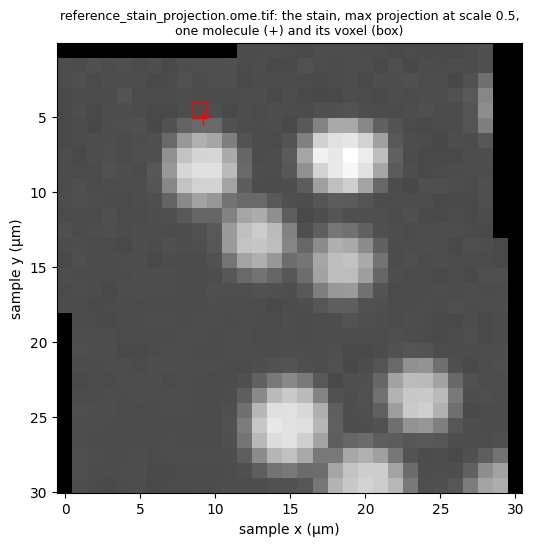

In [15]:
from starfinder.io import load_volume

fusion = record.record["fusion"] if EXPORTED else {"status": "off"}
if not EXPORTED:
    skipped("no export folder (the anndata extra is not installed)")
elif fusion["status"] != "written":
    skipped(f"the fuse part is {fusion['status']}: {fusion.get('reason')} {fusion.get('extra', '')}")
else:
    entry = fusion["outputs"][0]
    grid = fusion["grid"]
    print("file:", entry["path"], " image:", entry["image"], " dimensionality:", entry["dimensionality"],
          " projection:", entry["projection"], " factor_yx:", entry["factor_yx"], " dtype:", entry["dtype"])
    print("fusion grid: shape", grid["shape_zyx"], " spacing", grid["spacing_zyx"], " origin",
          [round(v, 6) for v in grid["origin_zyx"]], " FOVs", grid["fov_ids"])
    origins_zyx = approved.fovs[ORIGIN].to_numpy()
    o, s, n0 = np.min(origins_zyx, axis=0), np.asarray(SPACING, float), np.asarray(grid["shape_zyx"])
    n0_formula = np.floor((np.max(origins_zyx + (np.asarray(FOV_SHAPE) - 1) * s, axis=0) - o) / s + 1e-9) + 1
    k = entry["factor_yx"]
    formula = dict(spacing=[n0[0] * s[0], k * s[1], k * s[2]],
                   origin=[o[0] + s[0] * (n0[0] - 1) / 2, o[1] + s[1] * (k - 1) / 2, o[2] + s[2] * (k - 1) / 2],
                   shape=[1, int(np.ceil(n0[1] / k)), int(np.ceil(n0[2] / k))])
    loaded = load_volume(EXPORT / entry["path"])
    S, O = np.asarray(loaded.metadata.spacing_zyx), np.asarray(loaded.metadata.origin_zyx)
    shape = loaded.image.shape
    geometry = pd.DataFrame({"formula": formula, "file (load_volume)": dict(spacing=S.tolist(), origin=O.tolist(),
                                                                           shape=list(shape)),
                             "export.json": dict(spacing=entry["spacing_zyx"], origin=entry["origin_zyx"],
                                                 shape=entry["shape_zyx"])})
    with pd.option_context("display.max_colwidth", 120):
        display(geometry.map(lambda v: [round(x, 9) for x in v]))
    grid_ok = (np.array_equal(o, grid["origin_zyx"]) and np.array_equal(n0_formula, n0)
               and np.array_equal(s, grid["spacing_zyx"]))
    file_ok = (np.abs(S - formula["spacing"]).max() <= 1e-9 and np.abs(O - formula["origin"]).max() <= 1e-9
               and list(shape) == formula["shape"] and S.tolist() == entry["spacing_zyx"]
               and O.tolist() == entry["origin_zyx"])
    print("fusion grid equals the formulas:", grid_ok, " file geometry equals the formulas and the record:", file_ok)

    molecule = mols[(mols.assembly_status == "retained") & (mols.assignment_status == "assigned")].iloc[0]
    q = molecule[["sample_z", "sample_y", "sample_x"]].to_numpy(np.float64)
    v = np.floor((q - O) / S + 0.5).astype(int)
    support_ok = bool(np.all(O + (v - 0.5) * S <= q) and np.all(q < O + (v + 0.5) * S))
    inside = bool(np.all(v >= 0) and np.all(v < np.asarray(shape)))
    print(f"\nmolecule {molecule.spot_id} of {molecule.fov_id}: q = {np.round(q, 6).tolist()} µm")
    print("voxel v = floor((q - O) / S + 1/2):", v.tolist(), " inside the file:", inside,
          " its support contains q:", support_ok, " value there:", round(float(loaded.image[tuple(v)]), 3))
    assert grid_ok and file_ok and support_ok and inside and v[0] == 0

    fig, ax = plt.subplots(figsize=(6, 6))
    (Sy, Sx), (Oy, Ox) = S[1:], O[1:]
    ax.imshow(loaded.image[0], cmap="gray", interpolation="nearest",
              extent=(Ox - Sx / 2, Ox + (shape[2] - 0.5) * Sx, Oy + (shape[1] - 0.5) * Sy, Oy - Sy / 2))
    ax.add_patch(plt.Rectangle((Ox + (v[2] - 0.5) * Sx, Oy + (v[1] - 0.5) * Sy), Sx, Sy, fill=False, ec="red"))
    ax.plot(q[2], q[1], "r+", ms=12)
    ax.set_xlabel("sample x (µm)")
    ax.set_ylabel("sample y (µm)")
    ax.set_title(f"{entry['path']}: the stain, max projection at scale 0.5,\none molecule (+) and its voxel (box)",
                 fontsize=9)
    plt.show()

## 12. The label export at 0.25

`fuse_labels` writes the assembled label image `cell_labels.ome.tif`
([docs/sample-output-contract.md](../../docs/sample-output-contract.md), "Assembled label
export"): each FOV contributes only the cells it **retains** (rule LR4), each drawn whole from
the territory image assign sampled, with its `instance_id` (`1..N` over the rows of the sample
cell table, in its order; "Identities and source lookup"); the library places the FOVs at
interpolation order 0 with the first positive view, so labels are never blended or averaged.
It is off by default; at its default scale 0.25 it samples (`output_spacing`) rather than
averages, so the label grid has spacing `k·s` with `k = 4` in Y and X, origin `o` and size
`floor((max_f (origin_f + (n_f − 1)·s) − o) / (k·s) + 1e-9) + 1`, and keeps the fusion grid's Z;
the part checks the grid the library returns against these formulas within 1e-9 µm (L5 of
"Read-back checks"). Sampling at a coarse scale can drop a small territory: the section records
`ids_input`, `ids_output` and `absent_ids`.

The cell reads the label file back and checks that its spacing is four times the acquired
spacing in Y and X, within the page's 1e-9 µm (the file records the spacing the library
returned, whose last bit may differ), and equal to it in Z, and that every nonzero value is the
`instance_id` of a retained cell.

file: cell_labels.ome.tif  dtype: uint32  shape: (5, 15, 16)  rule: retained_cells  labels_scale_yx: 0.25  factor_yx: 4
label spacing (µm, Z Y X): [1.0, 1.9999999999999998, 2.0]  acquired: [1.0, 0.5, 0.5]  ratio: [1.0, 4.0, 4.0]
Y and X four times the acquired spacing (within 1e-9 µm): True  Z as acquired: True
record: n_ids_input 9  n_ids_output 9  absent_ids []  territory geometry: volume
label values: [2, 10, 12, 13, 16, 17, 18, 19, 21]
instance_id of the retained cells: [2, 10, 12, 13, 16, 17, 18, 19, 21]


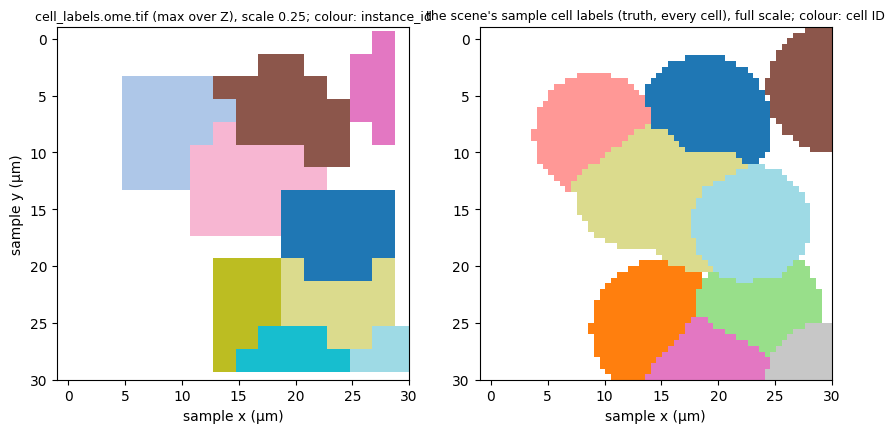

In [16]:
labels_section = record.record["labels"] if EXPORTED else {"status": "off"}
if not EXPORTED:
    skipped("no export folder (the anndata extra is not installed)")
elif labels_section["status"] != "written":
    skipped(f"the fuse_labels part is {labels_section['status']}: {labels_section.get('reason')} "
            f"{labels_section.get('extra', '')}")
else:
    entry = labels_section["outputs"][0]
    loaded_labels = load_volume(EXPORT / entry["path"])
    spacing = np.asarray(loaded_labels.metadata.spacing_zyx)
    acquired = np.asarray(SPACING, float)
    print("file:", entry["path"], " dtype:", loaded_labels.image.dtype, " shape:", loaded_labels.image.shape,
          " rule:", labels_section["rule"], " labels_scale_yx:", labels_section["labels_scale_yx"],
          " factor_yx:", labels_section["factor_yx"])
    print("label spacing (µm, Z Y X):", spacing.tolist(), " acquired:", acquired.tolist(),
          " ratio:", np.round(spacing / acquired, 12).tolist())
    yx_ok = bool(np.abs(spacing[1:] - 4 * acquired[1:]).max() <= 1e-9)
    z_ok = bool(spacing[0] == acquired[0])
    print("Y and X four times the acquired spacing (within 1e-9 µm):", yx_ok, " Z as acquired:", z_ok)
    # instance_id is 1..N over the rows of the sample cell table, in its order.
    instance_id = pd.Series(np.arange(1, len(assembly.cells) + 1), index=assembly.cells.index)
    retained_ids = set(map(int, instance_id[assembly.cells.assembly_status == "retained"]))
    values = set(map(int, np.unique(loaded_labels.image))) - {0}
    print("record: n_ids_input", labels_section["n_ids_input"], " n_ids_output", labels_section["n_ids_output"],
          " absent_ids", labels_section["absent_ids"], " territory geometry:", labels_section["territory_geometry"])
    print("label values:", sorted(values))
    print("instance_id of the retained cells:", sorted(retained_ids))
    assert yx_ok and z_ok and values <= retained_ids and len(values) == labels_section["n_ids_output"]

    fig, axes = plt.subplots(1, 2, figsize=(10, 5))
    shape = loaded_labels.image.shape
    origin = np.asarray(loaded_labels.metadata.origin_zyx)
    label_extent = (origin[2] - spacing[2] / 2, origin[2] + (shape[2] - 0.5) * spacing[2],
                    origin[1] + (shape[1] - 0.5) * spacing[1], origin[1] - spacing[1] / 2)
    axes[0].imshow(np.ma.masked_equal(loaded_labels.image.max(axis=0), 0) % 20, cmap="tab20",
                   interpolation="nearest", extent=label_extent)
    axes[0].set_title("cell_labels.ome.tif (max over Z), scale 0.25; colour: instance_id", fontsize=9)
    axes[1].imshow(np.ma.masked_equal(labels_2d, 0) % 20, cmap="tab20", interpolation="nearest", extent=extent)
    axes[1].set_title("the scene's sample cell labels (truth, every cell), full scale; colour: cell ID", fontsize=9)
    for ax in axes:
        ax.set_xlim(-1, 30)
        ax.set_ylim(30, -1)
        ax.set_xlabel("sample x (µm)")
    axes[0].set_ylabel("sample y (µm)")
    plt.show()

## 13. The SpatialData export and `lookup_source`

`export_spatialdata` writes one SpatialData store, `sample.zarr/`, from the saved assembly and
the files of parts 2 and 3 ([docs/sample-output-contract.md](../../docs/sample-output-contract.md),
"SpatialData export"): the molecules as points, the cell centroids as shapes, the cell table
and the expression table as tables, and each fused and label image **once**, read from its
OME-TIFF, with one resolution level and a transform to the sample frame (condition 5 of
"Sample position to image position"). An element that cannot be written is listed as omitted
with its reason. `check_export` of section 6 already read the store back (S1 to S8). The cell
lists the elements from the record and, with the `spatialdata` extra, opens the store.

**Tracing back.** Every row keeps its §2.9 key, so a molecule or a cell of the sample traces
back to the FOV and the saved assignment it came from: `lookup_source(folder, spot=…)` or
`lookup_source(folder, cell=…)` verifies the record's hashes and returns the FOV, the
assignment folder and the row in the FOV's §2.9 table. It needs only the assembly section, not
the store. The cell looks up one molecule and one excluded cell and checks the rows it names.

In [17]:
from starfinder.export import lookup_source

if not EXPORTED:
    skipped("no export folder (the anndata extra is not installed)")
else:
    section = record.record["spatialdata"]
    print("spatialdata part:", section["status"], " store:", section.get("store"), " reason:", section.get("reason"))
    elements = pd.DataFrame([{k: e.get(k, "") for k in ("name", "kind", "status", "rows", "model", "reason")}
                             for e in section.get("elements", [])])
    if len(elements):
        display(elements)
    if not EXTRAS["spatialdata"]:
        skipped("the spatialdata extra (starfinder[spatialdata]) is not installed: the store is not opened")
    elif section["status"] == "written":
        import spatialdata

        sdata = spatialdata.read_zarr(EXPORT / "sample.zarr")
        print("read_zarr:", {kind: sorted(getattr(sdata, kind)) for kind in ("images", "labels", "points", "shapes",
                                                                            "tables")})
        print("coordinate systems:", sorted(sdata.coordinate_systems))

    molecule = mols.iloc[0]
    found = lookup_source(EXPORT, spot=(molecule.spot_namespace, molecule.spot_id))
    print("\nlookup_source(spot):", clean({k: v for k, v in found.items() if not k.endswith("sha256")}))
    source_row = FOVS[found["fov_id"]].assignment_results["default"].molecules.iloc[found["row"]]
    print("  the named row holds the same molecule:", source_row.spot_id == molecule.spot_id)
    cell = cells[cells.assembly_status == "excluded"].iloc[0]
    found_cell = lookup_source(EXPORT, cell=(cell.cell_namespace, int(cell.cell_id)))
    print("lookup_source(cell):", clean({k: v for k, v in found_cell.items() if not k.endswith("sha256")}))
    source_cell = FOVS[found_cell["fov_id"]].assignment_results["default"].cells.sort_values("cell_id") \
        .iloc[found_cell["row"]]
    print("  the named row holds the same cell:", int(source_cell.cell_id) == int(cell.cell_id),
          "(an excluded cell: it stays traceable)")
    assert source_row.spot_id == molecule.spot_id and int(source_cell.cell_id) == int(cell.cell_id)

spatialdata part: written  store: sample.zarr  reason: None


,name,kind,status,rows,model,reason
0,molecules,points,written,99,,
1,cell_centroids,shapes,written,21,,
2,cells,table,written,21,,
3,expression,table,written,8,,
4,cells_unplaced,table,omitted,,,empty
5,molecules_unplaced,table,omitted,,,empty
6,reference_stain_projection,image,written,,Image2DModel,
7,cell_labels,labels,written,,Labels3DModel,


read_zarr: {'images': ['reference_stain_projection'], 'labels': ['cell_labels'], 'points': ['molecules'], 'shapes': ['cell_centroids'], 'tables': ['cells', 'expression']}
coordinate systems: ['sample']



lookup_source(spot): {'kind': 'spot', 'key': ['["sample-tiny-v1","sample","FOV_001",null]', 'csv:0'], 'fov_id': 'FOV_001', 'assignment_folder': '<workspace>/data/output/checkpoints/FOV_001/assignment/default', 'row': 0}
  the named row holds the same molecule: True


lookup_source(cell): {'kind': 'cell', 'key': ['["sample-tiny-v1","sample","FOV_001",null,"truth"]', 1], 'fov_id': 'FOV_001', 'assignment_folder': '<workspace>/data/output/checkpoints/FOV_001/assignment/default', 'row': 0}
  the named row holds the same cell: True (an excluded cell: it stays traceable)


## 14. A part that cannot run

A part **cannot run** when an optional extra it needs is not installed or a file it reads is
missing ([docs/sample-output-contract.md](../../docs/sample-output-contract.md), "When a part
cannot run"). That is not an error of the entry: the part is recorded `not_run` with its
reason, an `ExportIncompleteWarning` names it, the later parts that do not need its output
still run, and `export.json` has `complete: false`. Without `multiview-stitcher`, for example,
`fuse` and `fuse_labels` are `not_run` with the reason `extra_missing`.

The cell makes the other case, which needs no change to the environment: a second export into
a new folder, on the route per FOV as in section 6, asks for a second image, `missing=file:absent/{fov_id}.tif`, that no FOV has. The
fuse part is all or nothing, so it fuses no image and records `source_image_missing` with each
FOV; `fuse_labels` reads no source image and runs; the store omits the image elements with the
reason `part_not_run`. The folder still passes `check_export`: it equals its record.

In [18]:
from starfinder.export import FusionConfig

if not EXPORTED:
    skipped("no export folder (the anndata extra is not installed)")
else:
    INCOMPLETE = WORKSPACE / "incomplete" / SAMPLE
    missing_config = ExportConfig(route="per_fov", fuse_labels=True, export_spatialdata=True,
                                  fusion=FusionConfig(images=("reference_stain", "missing=file:absent/{fov_id}.tif")))
    with timed("Dataset.export with a missing source image"), synchronous(), \
            warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always", ExportIncompleteWarning)
        incomplete = dataset.export(SAMPLE, placement=PLACEMENT_DIR, config=missing_config, output_dir=INCOMPLETE)
    for warning in caught:
        if issubclass(warning.category, ExportIncompleteWarning):
            print(f"{warning.category.__name__}: {clean(warning.message)}")
    print("parts:", incomplete.parts, " complete:", incomplete.complete)
    fuse_section = incomplete.record["fusion"]
    print("fusion:", fuse_section["status"], fuse_section.get("reason"))
    omitted = [(e["name"], e.get("reason")) for e in incomplete.record["spatialdata"].get("elements", [])
               if e["status"] == "omitted"]
    print("store elements omitted:", omitted)
    print("files:", [p for p in files_under(INCOMPLETE) if not p.startswith("sample.zarr/")])
    check_export(INCOMPLETE)
    print("check_export: passed")
    assert not incomplete.complete and incomplete.parts["fuse"] == "not_run"

parts: {'assemble': 'written', 'fuse': 'not_run', 'segment': 'off', 'fuse_labels': 'written', 'export_spatialdata': 'written'}  complete: False
fusion: not_run source_image_missing
store elements omitted: [('cells_unplaced', 'empty'), ('molecules_unplaced', 'empty'), ('reference_stain_projection', 'part_not_run'), ('missing_projection', 'part_not_run')]
files: ['cell_labels.ome.tif', 'export.json', 'sample.h5ad', 'tables/cells.csv', 'tables/counts.csv', 'tables/fovs.csv', 'tables/molecules.csv']


check_export: passed


## 15. The two routes and the setting `route`

This section shows how a dataset chooses the route to its sample's cells, how the record says
which route ran and why, and what the export does when the route lacks its settings.

The two routes ([docs/sample-segmentation-contract.md](../../docs/sample-segmentation-contract.md),
"The route setting"; for users, [docs/workflow-downstream.md](../../docs/workflow-downstream.md),
"Two routes to a sample's cells"):

* the **route per FOV** (`per_fov`): each FOV is segmented and assigned on its own (§2.9), and
  `assemble` keeps each cell by the FOV that owns its ownership centroid, with the duplicate rule
  (section 16). Sections 6 to 14 used it;
* the **route after fusion** (`after_fusion`), for projection samples only: the fused Z maximum
  is segmented once, and the sample's molecules, each kept by the FOV that owns its position,
  are assigned to those cells (section 17).

`ExportConfig.route` sets the route. Not set (`None`), it follows `fusion.dimensionality` (RD1):
`projection` takes the route after fusion, `stack` and `both` the route per FOV. The `assembly`
section of `export.json` records `route` and `route_source` (`set` or `default`); the
`segmentation` section records the part `segment`, `off` on the route per FOV.

**The refusal.** A projection dataset with an assignment that sets neither `route` nor
`export.segmentation`, the settings of the route after fusion, is refused before anything is
written, with a `ValueError` that names both: no dataset changes route without a key that says
so. The cell shows that error, then an export with `dimensionality: both` and no route, which
takes the route per FOV by default (its fuse part is off: only the route is shown), and reads
back the route of section 6's export. Section 17 adds the route after fusion, by default and
set.

In [19]:
def route_row(export, config, exported):
    # The recorded route of an export, beside the settings that chose it.
    return dict(export=export, dimensionality=config.fusion.dimensionality, route_setting=config.route or "(not set)",
                route=exported.record["assembly"]["route"], route_source=exported.record["assembly"]["route_source"],
                segment=exported.record["segmentation"]["status"],
                segment_reason=exported.record["segmentation"].get("reason") or "-")


if not EXPORTED:
    skipped("no export folder (the anndata extra is not installed): Dataset.export refuses before the route check")
else:
    REFUSED = WORKSPACE / "refused" / SAMPLE
    refusal = error_of(lambda: dataset.export(SAMPLE, placement=PLACEMENT_DIR, config=ExportConfig(),
                                              output_dir=REFUSED))
    print("export of a projection with an assignment, without route and without export.segmentation:")
    print(" ", refusal)
    print("folder written:", REFUSED.exists())
    assert refusal.startswith("ValueError: ") and "export.segmentation" in refusal and "route: per_fov" in refusal
    assert not REFUSED.exists()

    BOTH = WORKSPACE / "both" / SAMPLE
    both_config = ExportConfig(fuse=False, fusion=FusionConfig(dimensionality="both"))
    both = dataset.export(SAMPLE, placement=PLACEMENT_DIR, config=both_config, output_dir=BOTH)
    ROUTE_ROWS = [route_row("section 6", CONFIG, record), route_row("dimensionality both", both_config, both)]
    display(pd.DataFrame(ROUTE_ROWS))
    assert [(r["route"], r["route_source"]) for r in ROUTE_ROWS] == [("per_fov", "set"), ("per_fov", "default")]
    assert all((r["segment"], r["segment_reason"]) == ("off", "route_per_fov") for r in ROUTE_ROWS)

export of a projection with an assignment, without route and without export.segmentation:
  ValueError: the route after fusion (route: after_fusion, the default for dimensionality 'projection') segments the fused projection and needs export.segmentation, the settings of that segmentation; set export.segmentation, or route: per_fov to assemble the per-FOV assignments
folder written: False


,export,dimensionality,route_setting,route,route_source,segment,segment_reason
0,section 6,projection,per_fov,per_fov,set,off,route_per_fov
1,dimensionality both,both,(not set),per_fov,default,off,route_per_fov


**What to take from this.** The route is a recorded choice: set, or by default from
`dimensionality`, and `export.json` says which. A projection dataset that names neither the
route nor the settings of the route after fusion stops before any file is written.

## 16. The duplicate rule of the route per FOV

This section shows how the route per FOV keeps one of two observations of a cell, on cells of
this sample that two FOVs both retain.

**The case.** The truth labels are imported with `relabel=False` (section 5), so a cell keeps its
scene ID in every FOV that sees it, and a cell that two FOVs retain shows as one `cell_id`
retained in two FOVs. The preset gives such cells without any change: the cell assembles the
same saved assignment folders in memory with the rule off,
`AssemblyConfig(duplicate_threshold=None)`, and lists them.

**The rule** ([docs/assembly-contract.md](../../docs/assembly-contract.md), "Retention", rule 8;
[docs/assembly-algorithms.md](../../docs/assembly-algorithms.md), "Duplicate rule"). The export of
section 6 has it on, at its default 0.5. Two cells of different FOVs that rule 1 retained are two
observations of one cell when their territories, each placed on the sample grid as the label
export places it, share at least half of the smaller territory. The retained cells are taken in
the order of decreasing territory size; a cell stays unless it pairs with a cell of another FOV
that already stays, and then it is excluded `duplicate_observation` and names that cell's
`obs_name` in `duplicate_of`. Its molecules are excluded `cell_duplicate_observation` and are not
given to the kept cell. Nothing is merged: the kept cell is the part its FOV saw.

The cell recomputes the rule from that definition: it places the retained cells of the rule-off
assembly on the sample grid at scale 1 (in Y and X spacing `s` and the smallest FOV origin, in Z
the fusion grid's; a grid voxel `v` shows the FOV voxel `floor(c + ½)`,
`c = (o + v·s − origin)/s`, where `0 ≤ c ≤ n − 1`), counts sizes and shared voxels there, and
decides in the order of decreasing size. It checks, exactly: the excluded observations and the
cells they name against that recomputation; that each names a retained cell of another FOV with
the same scene ID; the molecules of the excluded cells; the identities of section 9 with the rule
on and off; the flag `conflict` on both; and `sample.h5ad`, where each scene cell ID occurs once
with the rule on. The 0.5 is the decided default, not a value chosen for this sample.

In [20]:
from starfinder.export import fused_grid

if not EXPORTED:
    skipped("no export folder (the anndata extra is not installed)")
else:
    saved_inputs = [AssemblyInput(f, FOVS[f].reference_grid(),
                                  assignment=CHECKPOINTS.directory / f / "assignment" / "default") for f in FOV_IDS]
    rule_off = assemble(approved, saved_inputs, config=AssemblyConfig(duplicate_threshold=None))
    print("duplicate_threshold: the export", assembly.record["config"]["duplicate_threshold"],
          " the assembly in memory", rule_off.record["config"]["duplicate_threshold"])


    def retained_by_several(result):
        # The scene cell IDs that two or more FOVs retain, with those FOVs.
        kept = result.cells[result.cells.assembly_status == "retained"]
        fovs = kept.groupby(kept.cell_id.astype(int)).fov_id.agg(lambda f: sorted(f.astype(object)))
        return {cell: f for cell, f in fovs.items() if len(f) > 1}


    before, after = retained_by_several(rule_off), retained_by_several(assembly)
    print("scene cells retained by two or more FOVs: rule off", before, " rule on", after)
    assert len(before) >= 1 and after == {}

    # The rule recomputed from its definition (docs/assembly-algorithms.md, "Duplicate rule").
    S_GRID, O_GRID, N_GRID = fused_grid(approved, GRIDS, config=FusionConfig(scale_yx=1.0)).level("stack")
    fov_origin = approved.fovs.set_index("fov_id")[ORIGIN]


    def placed_territory(fov):
        # The FOV's territory on the sample grid: grid voxel v shows FOV voxel floor(c + 1/2), 0 <= c <= n - 1.
        origin, axes = fov_origin.loc[fov].to_numpy(np.float64), []
        for a in range(3):
            c = (O_GRID[a] + np.arange(N_GRID[a]) * S_GRID[a] - origin[a]) / SPACING[a]
            inside = (c >= -1e-9) & (c <= FOV_SHAPE[a] - 1 + 1e-9)
            axes.append((np.flatnonzero(inside), np.floor(c[inside] + 0.5).astype(int)))
        out = np.zeros(N_GRID, np.uint32)
        out[np.ix_(*(g for g, _ in axes))] = truth_labels(fov, GRIDS[fov], "truth")["cell"].labels[
            np.ix_(*(f for _, f in axes))]
        return out


    placed = {f: placed_territory(f) for f in FOV_IDS}
    retained_off = rule_off.cells[rule_off.cells.assembly_status == "retained"]
    size = {(r.fov_id, int(r.cell_id)): int((placed[r.fov_id] == int(r.cell_id)).sum()) for r in retained_off.itertuples()}
    stays, expected = [], set()
    for fov, cell_id in sorted(size, key=lambda k: (-size[k], FOV_IDS.index(k[0]), k[1])):
        mask = placed[fov] == cell_id
        partner = next((k for k in stays if k[0] != fov and min(size[k], size[(fov, cell_id)]) > 0
                        and (mask & (placed[k[0]] == k[1])).sum() / min(size[k], size[(fov, cell_id)]) >= 0.5), None)
        if partner is None:
            stays.append((fov, cell_id))
        else:
            expected.add((fov, cell_id, f"{SAMPLE}_{partner[0]}_{partner[1]}"))
    print("sample grid at scale 1:", tuple(N_GRID), " retained cells with the rule off:", len(size),
          " recomputed exclusions:", len(expected))

    duplicates = cells[cells.assembly_reason.astype(object) == "duplicate_observation"]
    by_name = cells.set_index("obs_name")
    named = [by_name.loc[d] for d in duplicates.duplicate_of]
    display(duplicates[["obs_name", "fov_id", "cell_id", "assembly_status", "assembly_reason", "duplicate_of",
                        "assembly_flags"]].assign(
        size_on_grid=[size[(r.fov_id, int(r.cell_id))] for r in duplicates.itertuples()],
        kept_size_on_grid=[size[(k.fov_id, int(k.cell_id))] for k in named]))
    found = {(r.fov_id, int(r.cell_id), r.duplicate_of) for r in duplicates.itertuples()}
    same_cell = all(k.assembly_status == "retained" and k.fov_id != r.fov_id and int(k.cell_id) == int(r.cell_id)
                    for k, r in zip(named, duplicates.itertuples()))
    print("excluded observations and duplicate_of equal the recomputation:", found == expected)
    print("each names a retained cell of another FOV with the same scene ID:", same_cell)
    assert found == expected and len(found) >= 1 and same_cell

    duplicate_keys = {(r.cell_namespace, int(r.cell_id)) for r in duplicates.itertuples()}
    of_duplicates = mols[[pd.notna(c) and (ns, int(c)) in duplicate_keys
                          for ns, c in zip(mols.cell_namespace, mols.cell_id)]]
    print("molecules of the excluded cells:", len(of_duplicates), " their reasons:",
          sorted(set(of_duplicates.assembly_reason.astype(object))),
          ' record["counts"]:', assembly.record["counts"]["molecules"]["excluded"]["cell_duplicate_observation"])
    assert set(of_duplicates.assembly_reason.astype(object)) <= {"cell_duplicate_observation"}
    assert len(of_duplicates) == assembly.record["counts"]["molecules"]["excluded"]["cell_duplicate_observation"]

    off_identities = check_identities(rule_off, export_inputs)
    on_identities = check_identities(assembly, export_inputs)
    print("identities 1 to 5, rule on:", all(on_identities.values()), " rule off:", all(off_identities.values()))
    assert all(on_identities.values()) and all(off_identities.values())
    print('cells flagged conflict: rule off', rule_off.record["counts"]["flags"]["conflict"], ' rule on',
          assembly.record["counts"]["flags"]["conflict"])

    obs_ids = by_name.loc[list(adata.obs_names), "cell_id"].astype(int)
    off_counted = rule_off.counted_cells().cell_id.astype(int)
    print("sample.h5ad rows:", adata.n_obs, " distinct scene cell IDs:", obs_ids.nunique(),
          " counted cells with the rule off:", len(off_counted), " distinct:", off_counted.nunique())
    assert obs_ids.is_unique and not off_counted.is_unique

duplicate_threshold: the export 0.5  the assembly in memory None
scene cells retained by two or more FOVs: rule off {2: ['FOV_002', 'FOV_004'], 8: ['FOV_001', 'FOV_002', 'FOV_003']}  rule on {}
sample grid at scale 1: (5, 60, 61)  retained cells with the rule off: 12  recomputed exclusions: 3


,obs_name,fov_id,cell_id,assembly_status,assembly_reason,duplicate_of,assembly_flags,size_on_grid,kept_size_on_grid
2,sample_FOV_001_8,FOV_001,8,excluded,duplicate_observation,sample_FOV_003_8,fov_edge;z_edge,1007,1194
4,sample_FOV_002_2,FOV_002,2,excluded,duplicate_observation,sample_FOV_004_2,fov_edge;z_edge,1040,1140
7,sample_FOV_002_8,FOV_002,8,excluded,duplicate_observation,sample_FOV_003_8,fov_edge;z_edge,912,1194


excluded observations and duplicate_of equal the recomputation: True
each names a retained cell of another FOV with the same scene ID: True
molecules of the excluded cells: 17  their reasons: ['cell_duplicate_observation']  record["counts"]: 17
identities 1 to 5, rule on: True  rule off: True
cells flagged conflict: rule off 5  rule on 0
sample.h5ad rows: 8  distinct scene cell IDs: 8  counted cells with the rule off: 11  distinct: 8


**What to take from this.** On the route per FOV a cell that two FOVs retain is counted once,
by its larger observation. The other observation stays in the tables, excluded with its reason
and the name of the kept cell, and its molecules go with it; nothing is merged, and the
identities hold with the rule on and off.

## 17. The route after fusion

This section runs the route after fusion on the same sample, with a segmentation that calls no
model, and checks that each cell is one row of the tables and of `sample.h5ad`.

**The settings** (`SampleSegmentationConfig` in `ExportConfig.segmentation`;
[docs/sample-segmentation-contract.md](../../docs/sample-segmentation-contract.md), "Where the
settings live"). Two runs, built as the fixture `seeded_runs` of
[docs/sample-segmentation-validation.md](../../docs/sample-segmentation-validation.md) builds
them:

* `nucleus`: an import (`LabelImportConfig`, `relabel=False` by default) of the scene's truth
  nuclei on the segmentation grid. That grid is the fused projection's; `fused_grid(…).level`
  gives it before any fusion (spacing 1 µm in Y and X at the default scale 0.5). Each pixel takes
  the label of the sample label grid's nearest voxel in Y and X, the largest over Z. The cell
  checks that no Y–X column of the scene holds two nuclei, so that projection keeps every nucleus
  whole. The scene's cells do overlap in Z, so they are not imported;
* `cell`: `seeded_watershed` (`sigma_um` 1.0) on the fused projection of `reference_merged`, the
  reference round's channel maximum (the role `amplicon`), seeded by `nucleus`: one cell grows
  from each nucleus over the smoothed amplicon signal. It runs on the CPU without a model and is
  used here for that reason; its cells are not compared with the truth.

The fused images are `reference_stain` and `reference_merged`. The assignment settings are
`AssignmentConfig()`, the ones `FOV.assign` used in section 5, so the two routes differ in their
cells and in how a molecule is kept, not in how it is assigned.

**`segment_fused` alone.** Each part can be called alone: `fuse` into a new folder, then
`segment_fused(folder, config=…, sample=…, identity=(dataset_id, sample_id))`, which reads the
fused projections that the `fusion` section lists, writes one label file per run,
`segmentation_<run>.ome.tif`, and the section `segmentation` of `export.json`. The first cell
does that and prints the runs.

In [21]:
from starfinder.assignment import AssignmentConfig
from starfinder.export import (FusionInput, SampleSegmentationConfig, SampleSegmentationRun, fuse, fused_grid,
                                      segment_fused)
from starfinder.segmentation import LabelImportConfig, SeededWatershedConfig

AFTER_FUSION = EXPORTED and EXTRAS["multiview-stitcher"]
if not AFTER_FUSION:
    skipped("the route after fusion fuses first: it needs the multiview-stitcher and anndata extras")
else:
    FUSION = FusionConfig(images=("reference_stain", "reference_merged"))
    segmentation_grid = fused_grid(approved, GRIDS, config=FUSION)
    S_SEG, O_SEG, N_SEG = segmentation_grid.level("projection")
    print("segmentation grid: shape", N_SEG, " spacing (µm)", S_SEG, " origin (µm)", [round(v, 6) for v in O_SEG])

    nuclei_zyx = scene.sample_labels["nucleus"]
    largest = nuclei_zyx.max(axis=0)
    smallest = np.where(nuclei_zyx > 0, nuclei_zyx, largest.max() + 1).min(axis=0)
    two_nuclei = int(((largest > 0) & (smallest != largest)).sum())
    cells_zyx = scene.sample_labels["cell"]
    smallest_cell = np.where(cells_zyx > 0, cells_zyx, cells_zyx.max() + 1).min(axis=0)
    two_cells = int(((cells_zyx.max(axis=0) > 0) & (smallest_cell != cells_zyx.max(axis=0))).sum())
    print("Y-X columns of the scene with two nuclei:", two_nuclei, " with two cells:", two_cells)
    assert two_nuclei == 0
    sample_grid = scene.sample_grid
    iy = np.floor((O_SEG[1] + np.arange(N_SEG[1]) * S_SEG[1] - sample_grid.origin_zyx[1]) / sample_grid.spacing_zyx[1]
                  + 0.5).astype(int)
    ix = np.floor((O_SEG[2] + np.arange(N_SEG[2]) * S_SEG[2] - sample_grid.origin_zyx[2]) / sample_grid.spacing_zyx[2]
                  + 0.5).astype(int)
    inside = ((iy >= 0) & (iy < largest.shape[0]))[:, None] & ((ix >= 0) & (ix < largest.shape[1]))[None, :]
    nuclei_on_grid = np.where(inside, largest[iy.clip(0, largest.shape[0] - 1)[:, None],
                                              ix.clip(0, largest.shape[1] - 1)[None, :]], 0).astype(np.uint32)
    NUCLEI_FILE = WORKSPACE / "truth" / "nuclei_projection.tif"
    save_volume(nuclei_on_grid[np.newaxis], NUCLEI_FILE, metadata=segmentation_grid.level_metadata("projection"))
    print("truth nuclei on the grid:", sorted(map(int, set(np.unique(nuclei_on_grid)) - {0})),
          " every nucleus of the scene:", sorted(map(int, set(np.unique(nuclei_zyx)) - {0})))

    SEGMENTATION = SampleSegmentationConfig(
        runs=(SampleSegmentationRun("nucleus", "nucleus", (), LabelImportConfig(str(NUCLEI_FILE), "nucleus")),
              SampleSegmentationRun("cell", "cell", (("amplicon", "reference_merged"),),
                                    SeededWatershedConfig(sigma_um=1.0), seeds="nucleus")),
        cells="cell", nuclei="nucleus", assignment=AssignmentConfig())

    PARTS = WORKSPACE / "parts" / SAMPLE
    fusion_inputs = [FusionInput(f, GRIDS[f], {"reference_stain": CHECKPOINTS.directory / f / STAIN_FILE,
                                               "reference_merged": OUTPUT / "images" / "ref_merged" / f"{f}.tif"})
                     for f in FOV_IDS]
    with timed("fuse and segment_fused called alone"), synchronous():
        fuse(approved, fusion_inputs, config=FUSION, output_dir=PARTS)
        alone = segment_fused(PARTS, config=SEGMENTATION, sample=SAMPLE, identity=(DATASET, SAMPLE))
    print("segment_fused:", alone.status, " grid:", alone.grid.shape_zyx, " cells:", alone.record["cells"],
          " nuclei:", alone.record["nuclei"])
    display(pd.DataFrame([{"run": r["name"], "target": r["target"], "inputs": r.get("inputs"),
                           "seeds": (r.get("seeds") or {}).get("run", "-"),
                           "label_namespace": r["label_namespace"], "file": clean(r["path"]), "n_labels": r["n_labels"]}
                          for r in alone.record["runs"]]))
    print("files of the folder:", files_under(PARTS))

segmentation grid: shape (1, 30, 31)  spacing (µm) (5.0, 1.0, 1.0)  origin (µm) [1.927787, 0.536808, -0.058818]
Y-X columns of the scene with two nuclei: 0  with two cells: 574
truth nuclei on the grid: [1, 2, 3, 4, 5, 6, 7, 8, 9]  every nucleus of the scene: [1, 2, 3, 4, 5, 6, 7, 8, 9]


segment_fused: written  grid: (1, 30, 31)  cells: cell  nuclei: nucleus


,run,target,inputs,seeds,label_namespace,file,n_labels
0,nucleus,nucleus,[],-,"[""sample-tiny-v1"",""sample"",null,null,""nucleus""]",segmentation_nucleus.ome.tif,9
1,cell,cell,"[{'role': 'amplicon', 'image': 'reference_merged'}]",nucleus,"[""sample-tiny-v1"",""sample"",null,null,""cell""]",segmentation_cell.ome.tif,9


files of the folder: ['export.json', 'reference_merged_projection.ome.tif', 'reference_stain_projection.ome.tif', 'segmentation_cell.ome.tif', 'segmentation_nucleus.ome.tif']


**`Dataset.export` on this route.** The same settings through the export entry, twice:

1. without `route`, so the default for a projection applies (`after_fusion`, `route_source`
   `default`), with the label export and the SpatialData export on, as in section 6. Section 18
   compares this folder with section 6's;
2. with `route: after_fusion` set and the cells expanded by 1 µm in the assignment settings, so
   that the assemble part also writes `territories.ome.tif`, the territories assign sampled.

The parts run in the order `fuse`, `segment`, `assemble`, `fuse_labels`, `export_spatialdata`.
The molecules come from the goodSpots tables of section 5, each kept by the FOV that owns its
position, as in a sample without segmentation. The cell checks: `check_export` on both folders
(which adds the conditions T1 to T5 of "The record" on this route); the recorded route and
source; that the export's label files equal those of `segment_fused` alone; each cell once (one
row per label of the cell run, unique cell keys and `obs_name`s, every cell `retained` without a
reason, so none `not_owner` or `duplicate_observation`, and one `sample.h5ad` row per counted
cell); the molecules' reasons; and the column `cell_namespace` of the molecule table, which names
the cell run for every molecule with a cell.

In [22]:
from starfinder.segmentation import ExpandLabelsConfig

if not AFTER_FUSION:
    skipped("the route after fusion fuses first: it needs the multiview-stitcher and anndata extras")
else:
    AFTER = OUTPUT / "export_after_fusion" / SAMPLE
    EXPANDED = OUTPUT / "export_after_fusion_expanded" / SAMPLE
    after_config = ExportConfig(fuse_labels=True, export_spatialdata=True, fusion=FUSION, segmentation=SEGMENTATION)
    expanded_config = ExportConfig(route="after_fusion", fusion=FUSION, segmentation=dataclasses.replace(
        SEGMENTATION, assignment=AssignmentConfig(expansion=ExpandLabelsConfig(distance=1.0, unit="um", mode="planar"))))
    with timed("Dataset.export on the route after fusion (two folders)"), synchronous(), \
            warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always", ExportIncompleteWarning)
        after = dataset.export(SAMPLE, placement=PLACEMENT_DIR, config=after_config, output_dir=AFTER)
        expanded = dataset.export(SAMPLE, placement=PLACEMENT_DIR, config=expanded_config, output_dir=EXPANDED)
    for warning in caught:
        if issubclass(warning.category, ExportIncompleteWarning):
            print(f"{warning.category.__name__}: {clean(warning.message)}")
    for exported in (after, expanded):
        check_export(exported.folder)
        print(clean(exported.folder), "\n  parts:", exported.parts, " complete:", exported.complete,
              "\n  files:", [p for p in files_under(exported.folder) if not p.startswith("sample.zarr/")],
              "and sample.zarr/" if (exported.folder / "sample.zarr").exists() else "")
    print("check_export: passed on both folders")
    assert all(exported.complete for exported in (after, expanded))
    assert "territories.ome.tif" in files_under(EXPANDED) and "territories.ome.tif" not in files_under(AFTER)

    ROUTE_ROWS += [route_row("route not set", after_config, after), route_row("route: after_fusion", expanded_config,
                                                                                 expanded)]
    display(pd.DataFrame(ROUTE_ROWS))
    assert [(r["route"], r["route_source"], r["segment"]) for r in ROUTE_ROWS[2:]] == [
        ("after_fusion", "default", "written"), ("after_fusion", "set", "written")]

    section = after.record["segmentation"]
    print("segmentation section:", sorted(section))
    print("  inputs:", {e["image"]: e["path"] for e in section["inputs"]["images"]}, " grid:",
          section["inputs"]["grid"]["shape_zyx"], " factor:", section["inputs"]["grid"].get("factor_yx"))
    print("  runs:", [(r["name"], r["target"], r["path"], r["n_labels"]) for r in section["runs"]],
          " cells:", section["cells"], " nuclei:", section["nuclei"], " device:", section["device"])
    print('assembly section: mode', after.record["assembly"]["mode"], ' segmentation_files',
          [e["path"] for e in after.record["assembly"]["segmentation_files"]])
    same_labels = all(np.array_equal(load_volume(AFTER / r["path"]).image, load_volume(PARTS / r["path"]).image)
                      for r in section["runs"])
    print("the export's label files equal those of segment_fused alone:", same_labels)
    assert same_labels

    for name, folder in (("route not set", AFTER), ("route: after_fusion, expanded", EXPANDED)):
        result = load_assembly(folder)
        fused_cells, fused_mols = result.cells, result.molecules
        labels = set(map(int, np.unique(load_volume(folder / "segmentation_cell.ome.tif").image))) - {0}
        keys = list(zip(fused_cells.cell_namespace.astype(object), fused_cells.cell_id.astype(int)))
        counted_rows = result.counted_cells()
        h5ad = anndata.read_h5ad(folder / "sample.h5ad")
        once = (set(fused_cells.cell_id.astype(int)) == labels and len(keys) == len(set(keys)) == len(labels)
                and fused_cells.obs_name.is_unique and list(h5ad.obs_names) == list(counted_rows.obs_name)
                and h5ad.obs_names.is_unique)
        reasons = set(fused_cells.assembly_reason.dropna().astype(object))
        with_cell = fused_mols.cell_id.notna()
        cell_run = next(r for r in section["runs"] if r["name"] == section["cells"])
        namespace_ok = ("cell_namespace" in fused_mols.columns and fused_mols.cell_namespace[~with_cell].isna().all()
                        and set(fused_mols.cell_namespace[with_cell].astype(object)) == {cell_run["label_namespace"]})
        print(f"\n{name}: cell rows {len(fused_cells)}, labels of the cell run {len(labels)}, counted cells "
              f"{len(counted_rows)}, sample.h5ad rows {h5ad.n_obs}")
        print("  each cell once:", once, " cell statuses:", sorted(set(fused_cells.assembly_status.astype(object))),
              " cell reasons:", sorted(reasons))
        print("  molecules: status by reason", {f"{s}/{r}": int(n) for (s, r), n in fused_mols.groupby(
            [fused_mols.assembly_status.astype(object), fused_mols.assembly_reason.astype(object).fillna("-")]).size().items()})
        print("  cell_namespace in the molecule table:", "cell_namespace" in fused_mols.columns,
              " it names the cell run for every molecule with a cell:", namespace_ok)
        assert once and set(fused_cells.assembly_status) == {"retained"} and not reasons
        assert not {"not_owner", "duplicate_observation"} & reasons and namespace_ok

<workspace>/data/output/export_after_fusion/sample 
  parts: {'assemble': 'written', 'fuse': 'written', 'segment': 'written', 'fuse_labels': 'written', 'export_spatialdata': 'written'}  complete: True 
  files: ['cell_labels.ome.tif', 'export.json', 'reference_merged_projection.ome.tif', 'reference_stain_projection.ome.tif', 'sample.h5ad', 'segmentation_cell.ome.tif', 'segmentation_nucleus.ome.tif', 'tables/cells.csv', 'tables/counts.csv', 'tables/fovs.csv', 'tables/molecules.csv'] and sample.zarr/


<workspace>/data/output/export_after_fusion_expanded/sample 
  parts: {'assemble': 'written', 'fuse': 'written', 'segment': 'written', 'fuse_labels': 'off', 'export_spatialdata': 'off'}  complete: True 
  files: ['export.json', 'reference_merged_projection.ome.tif', 'reference_stain_projection.ome.tif', 'sample.h5ad', 'segmentation_cell.ome.tif', 'segmentation_nucleus.ome.tif', 'tables/cells.csv', 'tables/counts.csv', 'tables/fovs.csv', 'tables/molecules.csv', 'territories.ome.tif'] 
check_export: passed on both folders


,export,dimensionality,route_setting,route,route_source,segment,segment_reason
0,section 6,projection,per_fov,per_fov,set,off,route_per_fov
1,dimensionality both,both,(not set),per_fov,default,off,route_per_fov
2,route not set,projection,(not set),after_fusion,default,written,-
3,route: after_fusion,projection,after_fusion,after_fusion,set,written,-


segmentation section: ['assignment', 'cells', 'cpu_s', 'device', 'inputs', 'nuclei', 'outputs', 'peak_rss_kib', 'route', 'runs', 'software', 'status', 'wall_s']
  inputs: {'reference_merged': 'reference_merged_projection.ome.tif'}  grid: [1, 30, 31]  factor: 2
  runs: [('nucleus', 'nucleus', 'segmentation_nucleus.ome.tif', 9), ('cell', 'cell', 'segmentation_cell.ome.tif', 9)]  cells: cell  nuclei: nucleus  device: cpu
assembly section: mode cells  segmentation_files ['segmentation_nucleus.ome.tif', 'segmentation_cell.ome.tif']
the export's label files equal those of segment_fused alone: True

route not set: cell rows 9, labels of the cell run 9, counted cells 9, sample.h5ad rows 9
  each cell once: True  cell statuses: ['retained']  cell reasons: []
  molecules: status by reason {'excluded/not_owner': 35, 'retained/-': 64}
  cell_namespace in the molecule table: True  it names the cell run for every molecule with a cell: True



route: after_fusion, expanded: cell rows 9, labels of the cell run 9, counted cells 9, sample.h5ad rows 9
  each cell once: True  cell statuses: ['retained']  cell reasons: []
  molecules: status by reason {'excluded/not_owner': 35, 'retained/-': 64}
  cell_namespace in the molecule table: True  it names the cell run for every molecule with a cell: True


**What to take from this.** On the route after fusion a cell across a seam is one cell of one
segmentation, so the tables and `sample.h5ad` hold one row per cell and no cell is excluded. The
molecules keep their rule, one FOV per position, and each names its cell by the cell key. The
folder has the same files as on the route per FOV, plus the label file of each run and, when
the cells are expanded, `territories.ome.tif`.

## 18. `compare_routes`: the two routes side by side

This section compares the folders of the two routes for this sample with `compare_routes` and
draws both routes' cells on the fused projection.

`compare_routes(per_fov, after_fusion, threshold=0.5, output=None)`
([docs/sample-segmentation-contract.md](../../docs/sample-segmentation-contract.md), "The
consistency check of the two routes") first checks that the two folders hold one sample, one
placement, one gene list and one molecule population. It places the counted cells of both routes
on the segmentation grid of the route after fusion, the route per FOV's territories as the label
export places them, and counts the pixels each pair of cells shares. The share of a pair is its
shared pixels divided by the pixels of the smaller cell, the duplicate rule's measure. A pair is
matched when its share is at least the threshold and each cell is the other's partner of highest
share. Each molecule key gets one of six categories. The report decides nothing and writes
nothing without `output`. Neither route is a truth, and agreement does not show that either is
right. The threshold is the function's default, not a value chosen for this sample.

The folders are section 6's (route per FOV) and section 17's first (route after fusion), made
with the same assignment settings. The cell hashes every file of both folders before and after
the call. It prints the summary, the matched pairs and the cells in no matched pair, and checks
that the summary's cell counts equal the counted cells of each folder's tables, that every
matched pair's share is at least the threshold, and that no file changed. The figure shows the
fused `reference_stain` projection of the route after fusion with the outline of each counted
cell of both routes, placed by the rule `compare_routes` uses, and the ownership boundaries.

threshold: 0.5  measure: starfinder.assembly._duplicates.share
  cells: {'per_fov': 8, 'after_fusion': 9}
  pairs: 20
  matched_pairs: 8
  cells_in_no_matched_pair: {'per_fov': 0, 'after_fusion': 1}
  after_fusion_cells_sharing_with_several: 1
  per_fov_cells_sharing_with_several: 2
  retained_molecules: {'per_fov': 59, 'after_fusion': 64, 'both': 54}
  molecule_categories: {'same_cell': 32, 'different_cells': 14, 'cell_on_one_route': 6, 'no_cell_on_both': 2, 'retained_on_one_route': 15, 'excluded_on_both': 30}
summary cells equal the counted cells of each folder: True

matched pairs:


,per_fov_obs_name,after_fusion_obs_name,per_fov_size,after_fusion_size,shared,share,centroid_distance,per_fov_fov_edge
0,sample_FOV_001_4,sample_FOV_001_4,89,54,40,0.7407,2.5262,False
2,sample_FOV_003_1,sample_FOV_003_1,108,31,31,1.0000,0.4787,False
6,sample_FOV_003_5,sample_FOV_003_5,42,17,11,0.6471,1.0931,True
9,sample_FOV_003_8,sample_FOV_001_9,99,59,44,0.7458,3.1737,True
10,sample_FOV_004_2,sample_FOV_002_2,68,21,21,1.0000,0.8968,True
13,sample_FOV_004_3,sample_FOV_004_3,77,71,51,0.7183,2.6392,False
17,sample_FOV_004_6,sample_FOV_004_6,36,35,21,0.6000,3.1487,True
19,sample_FOV_004_7,sample_FOV_004_7,26,7,7,1.0000,1.3957,True


matched pairs at or above the threshold: True
cells in no matched pair: {'per_fov': [], 'after_fusion': ['sample_FOV_003_8']}
pairs with a share above 0 that are not matched: 12

counts per matched pair:


,per_fov_cell_namespace,per_fov_cell_id,after_fusion_cell_namespace,after_fusion_cell_id,per_fov_whole,after_fusion_whole,whole_difference,gene_difference
0,"[""sample-tiny-v1"",""sample"",""FOV_001"",null,""truth""]",4,"[""sample-tiny-v1"",""sample"",null,null,""cell""]",4,10,12,2,2
1,"[""sample-tiny-v1"",""sample"",""FOV_003"",null,""truth""]",1,"[""sample-tiny-v1"",""sample"",null,null,""cell""]",1,8,4,-4,4
2,"[""sample-tiny-v1"",""sample"",""FOV_003"",null,""truth""]",5,"[""sample-tiny-v1"",""sample"",null,null,""cell""]",5,4,2,-2,2
3,"[""sample-tiny-v1"",""sample"",""FOV_003"",null,""truth""]",8,"[""sample-tiny-v1"",""sample"",null,null,""cell""]",9,5,8,3,5
4,"[""sample-tiny-v1"",""sample"",""FOV_004"",null,""truth""]",2,"[""sample-tiny-v1"",""sample"",null,null,""cell""]",2,5,2,-3,3
5,"[""sample-tiny-v1"",""sample"",""FOV_004"",null,""truth""]",3,"[""sample-tiny-v1"",""sample"",null,null,""cell""]",3,10,13,3,5
6,"[""sample-tiny-v1"",""sample"",""FOV_004"",null,""truth""]",6,"[""sample-tiny-v1"",""sample"",null,null,""cell""]",6,5,8,3,5
7,"[""sample-tiny-v1"",""sample"",""FOV_004"",null,""truth""]",7,"[""sample-tiny-v1"",""sample"",null,null,""cell""]",7,4,0,-4,4


molecule keys: 99  by category: {'same_cell': 32, 'excluded_on_both': 30, 'retained_on_one_route': 15, 'different_cells': 14, 'cell_on_one_route': 6, 'no_cell_on_both': 2}
no file of either folder changed: True


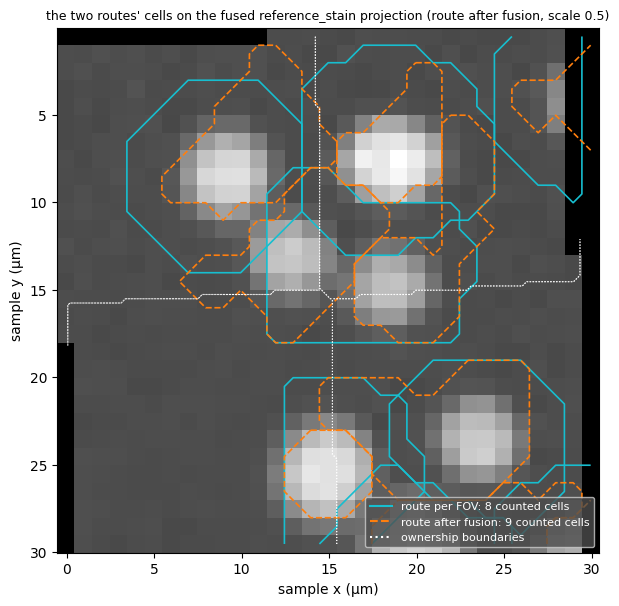

In [23]:
import hashlib

from starfinder.export import compare_routes


def folder_hashes(folder):
    # The SHA-256 of every file of a folder, by relative path.
    return {p: hashlib.sha256((Path(folder) / p).read_bytes()).hexdigest() for p in files_under(folder)}


if not AFTER_FUSION:
    skipped("no folder of the route after fusion (section 17 was skipped)")
else:
    hashes_before = {folder: folder_hashes(folder) for folder in (EXPORT, AFTER)}
    with timed("compare_routes"):
        comparison = compare_routes(EXPORT, AFTER)
    unchanged = hashes_before == {folder: folder_hashes(folder) for folder in (EXPORT, AFTER)}
    summary = comparison.summary
    THRESHOLD = comparison.record["threshold"]
    print("threshold:", THRESHOLD, " measure:", comparison.record["measure"])
    for key, value in summary.items():
        if key != "share_bins":
            print(f"  {key}: {value}")
    per_fov_counted = assembly.counted_cells()
    after_fusion_counted = load_assembly(AFTER).counted_cells()
    cells_ok = summary["cells"] == {"per_fov": len(per_fov_counted), "after_fusion": len(after_fusion_counted)}
    print("summary cells equal the counted cells of each folder:", cells_ok)

    pairs = comparison.pairs
    matched = pairs[pairs.matched]
    print("\nmatched pairs:")
    display(matched[["per_fov_obs_name", "after_fusion_obs_name", "per_fov_size", "after_fusion_size", "shared", "share",
                     "centroid_distance", "per_fov_fov_edge"]].round(4))
    matched_ok = len(matched) == summary["matched_pairs"] and bool((matched.share >= THRESHOLD).all())
    print("matched pairs at or above the threshold:", matched_ok)
    unmatched = {"per_fov": sorted(set(per_fov_counted.obs_name) - set(matched.per_fov_obs_name)),
                 "after_fusion": sorted(set(after_fusion_counted.obs_name) - set(matched.after_fusion_obs_name))}
    print("cells in no matched pair:", unmatched)
    print("pairs with a share above 0 that are not matched:", int((~pairs.matched).sum()))
    print("\ncounts per matched pair:")
    display(comparison.counts)
    categories = comparison.molecules.category.astype(object).value_counts()
    print("molecule keys:", len(comparison.molecules), " by category:", categories.to_dict())
    print("no file of either folder changed:", unchanged)
    assert cells_ok and matched_ok and unchanged
    assert {r: len(v) for r, v in unmatched.items()} == summary["cells_in_no_matched_pair"]
    assert int(categories.sum()) == len(comparison.molecules) == len(mols)

    fused_entry = next(o for o in after.record["fusion"]["outputs"] if o["image"] == "reference_stain")
    fused_image = load_volume(AFTER / fused_entry["path"])
    (Sy, Sx), (Oy, Ox) = fused_image.metadata.spacing_zyx[1:], fused_image.metadata.origin_zyx[1:]
    ny, nx = fused_image.image.shape[1:]
    ys, xs = Oy + np.arange(ny) * Sy, Ox + np.arange(nx) * Sx
    fused_labels = load_volume(AFTER / "segmentation_cell.ome.tif").image[0]

    def placed(fov, cell_id):
        # A counted cell of the route per FOV on the segmentation grid: grid pixel v shows the FOV pixel
        # floor(c + 1/2), c = (O + v S - origin) / s, inside the FOV's voxel-centre extent, any plane.
        origin = approved.fovs.set_index("fov_id").loc[fov, ORIGIN].to_numpy(np.float64)
        (_, n_y, n_x), (_, s_y, s_x) = FOV_SHAPE, SPACING
        cy, cx = (ys - origin[1]) / s_y, (xs - origin[2]) / s_x
        in_y, in_x = (cy >= 0) & (cy <= n_y - 1), (cx >= 0) & (cx <= n_x - 1)
        fy, fx = np.floor(cy[in_y] + 0.5).astype(int), np.floor(cx[in_x] + 0.5).astype(int)
        territory = truth_labels(fov, GRIDS[fov], "truth")["cell"].labels
        mask = np.zeros((ny, nx), bool)
        mask[np.ix_(in_y, in_x)] = (territory[:, fy][:, :, fx] == cell_id).any(axis=0)
        return mask

    fig, ax = plt.subplots(figsize=(7, 7))
    ax.imshow(fused_image.image[0], cmap="gray", interpolation="nearest",
              extent=(Ox - Sx / 2, Ox + (nx - 0.5) * Sx, Oy + (ny - 0.5) * Sy, Oy - Sy / 2))
    for r in per_fov_counted.itertuples():
        ax.contour(xs, ys, placed(r.fov_id, int(r.cell_id)).astype(float), levels=[0.5], colors="tab:cyan",
                   linewidths=1.2)
    for cell_id in after_fusion_counted.cell_id.astype(int):
        ax.contour(xs, ys, (fused_labels == cell_id).astype(float), levels=[0.5], colors="tab:orange",
                   linewidths=1.2, linestyles="dashed")
    fine_y, fine_x = np.linspace(ys[0], ys[-1], 4 * ny), np.linspace(xs[0], xs[-1], 4 * nx)
    fy_, fx_ = np.meshgrid(fine_y, fine_x, indexing="ij")
    owner_at = regions.owner(np.column_stack([np.zeros(fy_.size), fy_.ravel(), fx_.ravel()]))
    owner_index = np.array([np.nan if pd.isna(o) else index[o] for o in owner_at], float).reshape(fy_.shape)
    for k in range(len(FOV_IDS)):
        # Masked where no FOV owns the point, so that only the boundaries between owners are drawn.
        ax.contour(fine_x, fine_y, np.where(np.isnan(owner_index), np.nan, (owner_index == k).astype(float)),
                   levels=[0.5], colors="white", linewidths=0.8, linestyles="dotted")
    ax.plot([], [], color="tab:cyan", label=f"route per FOV: {len(per_fov_counted)} counted cells")
    ax.plot([], [], color="tab:orange", ls="--", label=f"route after fusion: {len(after_fusion_counted)} counted cells")
    ax.plot([], [], color="white", ls=":", label="ownership boundaries")
    ax.legend(loc="lower right", fontsize=8, facecolor="0.3", labelcolor="white")
    ax.set_xlabel("sample x (µm)")
    ax.set_ylabel("sample y (µm)")
    ax.set_title("the two routes' cells on the fused reference_stain projection (route after fusion, scale 0.5)",
                 fontsize=9)
    plt.show()

**What to take from this.** `compare_routes` reads two folders and reports which cells of the
two routes cover the same pixels, how their counts differ and where each molecule lands on each
route. It changes no file and accepts or rejects nothing. Its numbers describe this synthetic
sample with these two segmentations, the truth labels per FOV against a seeded watershed after
fusion; they do not say which route is right.

## 19. The cell flags on the two routes

This section shows what the cell flags `conflict`, `unclaimed` and `fov_edge` say on the route
per FOV, and that the route after fusion does not define them.

On the route per FOV each FOV's cells come from its own segmentation, so assembly marks what it
cannot decide ([docs/assembly-contract.md](../../docs/assembly-contract.md), "Flags"):

* `fov_edge`: the cell's territory touches the first or last index of its FOV's grid in Y or X,
  so the FOV may have seen only part of the cell. The duplicate rule does not change it: the kept
  observation of a cut cell is still the part its FOV saw;
* `conflict`: a retained cell whose ownership centroid lies inside the territory of a retained
  cell of another FOV, or the reverse, so the same cell may be retained twice. A cell the
  duplicate rule excludes is no longer retained, so its pair no longer raises the flag;
* `unclaimed`: an excluded (`not_owner`) cell where the owning FOV retains no cell, so the cell
  may be retained by no FOV. Decided on 2026-10-10: no rule is added for these cells, and the
  flag keeps marking them.

On the route after fusion the cells come from one segmentation of the whole sample: there is no
second observation and no other FOV's territory to test. None of the flags is defined there
(choice FL1 of [docs/sample-segmentation-contract.md](../../docs/sample-segmentation-contract.md),
"The cells"): `assembly_flags` and `conflict_with` are empty on every row, the `assembly` section
records an empty `flags.computed` and `flags.applicable` false, and a cell at the sample's outer
border is not marked. The cell counts each flag on both routes and prints both records.

In [24]:
if not EXPORTED:
    skipped("no export folder (the anndata extra is not installed)")
else:
    FLAGS = ("fov_edge", "conflict", "unclaimed")


    def flag_counts(frame):
        flags = frame.assembly_flags.fillna("").astype(str).str.split(";")
        return {flag: int(flags.map(lambda f: flag in f).sum()) for flag in FLAGS}


    table = {"route per FOV (section 6)": flag_counts(cells)}
    records = {"route per FOV (section 6)": assembly.record["flags"]}
    if AFTER_FUSION:
        fused_cells = load_assembly(AFTER).cells
        table["route after fusion (section 17)"] = flag_counts(fused_cells)
        records["route after fusion (section 17)"] = after.record["assembly"]["flags"]
    display(pd.DataFrame(table).T)
    for route, flags_record in records.items():
        print(f"{route}: flags {flags_record}")
    flagged = cells[cells.assembly_flags.fillna("").astype(str) != ""]
    print("\nroute per FOV, cells by status and reason (rows) and flags (columns):")
    display(pd.crosstab([flagged.assembly_status.astype(object), flagged.assembly_reason.astype(object).fillna("-")],
                        flagged.assembly_flags.astype(object)))
    assert set(FLAGS) <= set(assembly.record["flags"]["computed"])
    if AFTER_FUSION:
        assert fused_cells.assembly_flags.fillna("").astype(str).eq("").all()
        assert fused_cells.conflict_with.fillna("").astype(str).eq("").all()
        assert after.record["assembly"]["flags"]["computed"] == [] and after.record["assembly"]["flags"]["applicable"] is False

,fov_edge,conflict,unclaimed
route per FOV (section 6),18,0,0
route after fusion (section 17),0,0,0


route per FOV (section 6): flags {'computed': ['fov_edge', 'z_edge', 'conflict', 'unclaimed', 'outside_owner_region', 'cell_unclaimed'], 'conflicts': True}
route after fusion (section 17): flags {'computed': [], 'conflicts': True, 'applicable': False}

route per FOV, cells by status and reason (rows) and flags (columns):


assembly_flags                         fov_edge;z_edge  z_edge
assembly_status assembly_reason                               
excluded        duplicate_observation                3       0
                not_owner                            9       0
retained        -                                    6       3

**What to take from this.** The flags are how the route per FOV points at cells it may have
cut, doubled or lost at a seam; they never change a status. On the route after fusion a cell is
one cell of one segmentation, the flags are not computed, and the record says so.

## 20. What is deferred: viewers, a fused 3D stack, merging of cells

This section lists what the §2.10 implementation leaves for later, and shows the refusal that
marks one of them in the code.

* **Viewers.** The export writes standard formats (OME-TIFF, OME-Zarr on request, SpatialData,
  AnnData), and the checks of this notebook and of `check_export` read them back with the
  libraries that wrote them. Whether a viewer (napari, the SpatialData viewers, QuPath, Fiji)
  opens them and places every layer where it belongs has not been checked: reopening the export
  in a viewer is deferred (decision of 2026-10-05), and `export.json` says so in
  `viewer_qualification`. No viewer runs here.
* **Segmentation of a fused 3D stack.** The route after fusion is built for projection samples.
  Segmenting a fused stack block by block, with a chunked label file, is not specified (decided
  on 2026-10-09), so a 3D sample takes the route per FOV. `route: after_fusion` with
  `dimensionality: stack` is refused before anything is written; the cell shows the error.
* **Merging of cells across FOVs.** Neither route merges observations of a cell (decided on
  2026-10-09). The duplicate rule of the route per FOV excludes the second observation and does
  not complete a cell cut by a FOV edge (section 16); the route after fusion segments each cell
  once (section 17).

Also outside this notebook, by design: BigStitcher, which runs in Fiji as an engine task
(`bigstitcher_macro`, then `import_bigstitcher`); real data, whose examples are separate issues;
any comparison or ranking of the placement backends or of the two routes; and any accuracy
claim.

In [25]:
if not EXPORTED:
    skipped("no export folder (the anndata extra is not installed)")
else:
    print("export.json viewer_qualification:", record.record.get("viewer_qualification"))
    for name in ("fusion", "labels", "spatialdata"):
        section = record.record[name]
        print(f"  {name}: {section.get('viewer_qualification', '(the part is ' + section['status'] + ')')}")
    STACK = WORKSPACE / "stack" / SAMPLE
    stack_refusal = error_of(lambda: dataset.export(
        SAMPLE, placement=PLACEMENT_DIR, config=ExportConfig(route="after_fusion", fusion=FusionConfig(dimensionality="stack")),
        output_dir=STACK))
    print("\nroute: after_fusion with dimensionality: stack:\n ", stack_refusal)
    print("folder written:", STACK.exists())
    assert stack_refusal.startswith("ValueError: ") and "stack" in stack_refusal and "route: per_fov" in stack_refusal
    assert not STACK.exists()

export.json viewer_qualification: deferred
  fusion: deferred
  labels: deferred
  spatialdata: deferred

route: after_fusion with dimensionality: stack:
  ValueError: segmentation after fusion is specified for projection samples only; a dataset with dimensionality 'stack' is segmented per FOV (route: per_fov)
folder written: False


**What to take from this.** Viewers, the segmentation of a fused 3D stack and the merging of cells
across FOVs are left for later; the code refuses the second rather than doing something else.

## 21. Clean up

The notebook wrote only inside its temporary workspace: the saved scene, the dataset's
reference images, goodSpots tables, assignment folders and stains, the placement, the export
folders of sections 6, 14, 15 and 17, the folder of the parts called alone and the truth nuclei
file of section 17. The
next cell checks the sizes against the routine bound of the §2.10 resource exceptions (one
scene of at most 16 × 256 × 256, cut into tiles), prints the wall-clock time of the slower steps,
measured by `timed` at one thread on this host (these times vary between runs and are
indicative only; they are the only printed numbers that do), and reports what was written. The
last cell removes the workspace.

In [26]:
BOUND_ZYX = (16, 256, 256)
arrays = {"scene (sample label grid)": scene.sample_labels["cell"].shape,
          "FOV rounds (ZYX)": next(iter(scene.fovs.values())).rounds[ROUNDS[0]].shape[:3],
          "FOV stain": next(iter(scene.stains.values())).shape}
if EXPORTED and record.record["fusion"]["status"] == "written":
    arrays["fusion grid"] = tuple(record.record["fusion"]["grid"]["shape_zyx"])
if AFTER_FUSION:
    arrays["segmentation grid (route after fusion)"] = tuple(N_SEG)
for name, shape in arrays.items():
    print(f"{name}: {shape}")
within = all(all(n <= b for n, b in zip(shape, BOUND_ZYX)) for shape in arrays.values())
print("every array within 16 x 256 x 256:", within, " FOVs:", len(FOV_IDS), "(a 2 x 2 grid)")
assert within
written = [p for p in WORKSPACE.rglob("*") if p.is_file()]
print(f"{len(written)} files written, all under {sorted({p.relative_to(WORKSPACE).parts[0] for p in written})}")
print("\nwall-clock time of the slower steps (one thread, this host; indicative, varies between runs):")
for label, seconds in TIMINGS.items():
    print(f"  {seconds:6.2f} s  {label}")

scene (sample label grid): (6, 63, 63)
FOV rounds (ZYX): (5, 36, 36)
FOV stain: (5, 36, 36)
fusion grid: (5, 60, 61)
segmentation grid (route after fusion): (1, 30, 31)
every array within 16 x 256 x 256: True  FOVs: 4 (a 2 x 2 grid)
973 files written, all under ['both', 'data', 'incomplete', 'parts', 'scene', 'truth']

wall-clock time of the slower steps (one thread, this host; indicative, varies between runs):
    0.42 s  generate and save the sample scene (sample-tiny-v1, seed 42)
    1.92 s  stitch with multiview_stitcher (4 FOVs, binning 1)
    0.82 s  per FOV: FOV.run, import_labels, FOV.assign with checkpoints (4 FOVs)
    2.67 s  Dataset.export: assemble, fuse, fuse_labels, export_spatialdata
    0.36 s  the truth path in memory: assign_molecules and assemble
    2.22 s  Dataset.export with a missing source image
    0.24 s  fuse and segment_fused called alone
    3.37 s  Dataset.export on the route after fusion (two folders)
    0.24 s  compare_routes


In [27]:
_workspace.cleanup()
print("workspace removed:", not WORKSPACE.exists())

workspace removed: True
